In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import torch.nn.functional as F
from google.colab import drive
drive.mount('/content/drive')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install --force-reinstall sympy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 132.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 44.8 MB/s eta 0:00:00
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0


The idea is to train a simple model:
$$ \text{GeoEx}(x) = \text{MLP}(\vec{\lambda}\odot [R⋅(\vec{x}+\vec{t})])$$
with loss:
$$ L(y, x, \text{GeoEx}) = \text{MAE}(y,\text{GeoEx}(x))+\alpha \|\vec{\lambda}\|_1 + \beta \|(R\cdot R^T-I)\|_2$$
The tuple of $(R, \vec{t}, \vec{\lambda})$ represent the geometric transformation of data. As coefficients of $\vec{\lambda}$ are under $L_1$ regularization they represent 'turning off' majority of dimensions. Rotation $R$ and translation $\vec{t}$ define a affine transform.

In [ ]:
class GeometryExtractor(nn.Module):
    def __init__(self, latent_dim, compressed_dim, feature_out_dim):
        super(GeometryExtractor, self).__init__()

        self.t_vec = nn.Parameter(torch.zeros(latent_dim))
        self.rotation_matrix = nn.Parameter(torch.eye(latent_dim))
        self.lambda_vec = nn.Parameter(torch.ones(latent_dim))

        # 4. Feature Extractor
        self.feature_extractor = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, feature_out_dim)
        )

    def forward(self, x):
        x = x + self.t_vec
        x = torch.matmul(x, self.rotation_matrix)
        x = x * self.lambda_vec

        # Feature Extraction
        logits = self.feature_extractor(x)
        return logits

In [ ]:
# --- 2. Data Preparation ---
# Assuming X and y are already loaded as torch Tensors
def Geometry_Extraction(X, y, target_lambda = 2, verbose = 2, n_epochs = 100, beta_coeff = 1.35, alpha_coeff=1.35, out_dim = 1):
  dataset = TensorDataset(X, y.unsqueeze(1) if y.ndim == 1 else y)
  train_size = int(0.8 * len(dataset))
  test_size = len(dataset) - train_size
  train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

  train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
  test_loader = DataLoader(test_dataset, batch_size=256)

  # --- 3. Training Setup ---
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  H_model = GeometryExtractor(latent_dim=192, compressed_dim=192, feature_out_dim=out_dim).to(device)
  optimizer = optim.Adam(H_model.parameters(), lr=1e-3)

  # Hyperparameters for Regularization
  alpha_l1 = 0.01  # Sparsity strength
  beta_ortho = 0.01 # Orthogonality strength

  # --- 4. Training Loop ---
  epochs = n_epochs
  # Threshold for considering a lambda coefficient "active"
  sparsity_threshold = 1e-2

  if verbose > 0:
    print(f"{'Epoch':<6} | {'Total':<8} | {'MAE':<8} | {'L1':<8} | {'Ortho':<8} | {'Non-Zero'}")
    print("-" * 80)

  for epoch in range(epochs):
      H_model.train()
      # Metrics trackers
      running_mae, running_l1, running_ortho, running_total = 0, 0, 0, 0

      for batch_X, batch_y in train_loader:
          batch_X, batch_y = batch_X.to(device), batch_y.to(device)

          # Forward pass
          preds = H_model(batch_X)

          # Loss Components
          mae_loss = F.l1_loss(preds, batch_y) # For monitoring

          sorted_vec, _ = torch.sort(H_model.lambda_vec, descending=True)
          l1_reg = torch.norm(sorted_vec[target_lambda:], p=1)

          R = H_model.rotation_matrix
          eye = torch.eye(R.size(0), device=device)
          ortho_dist = torch.norm(torch.matmul(R, R.t()) - eye, p=2)

          # Optimization Goal
          total_loss = mae_loss + (alpha_l1 * l1_reg) + (beta_ortho * ortho_dist)

          optimizer.zero_grad()
          total_loss.backward()
          optimizer.step()

          # Accumulate for printing
          running_total += total_loss.item()
          running_mae += mae_loss.item()
          running_l1 += alpha_l1*l1_reg.item()
          running_ortho += beta_ortho*ortho_dist.item()

      # Calculate Sparsity (count non-zero lambda coefficients)
      with torch.no_grad():
          non_zero_count = (H_model.lambda_vec.abs() > sparsity_threshold).sum().item()
          diff = torch.norm(torch.matmul(R, R.t()) - eye, p='fro')
          det = torch.det(R)

      if epoch == 1:
        n = len(train_loader)
        perc_mae = 100*running_mae / running_total
        perc_l1 = 100*running_l1 / running_total
        perc_ortho = 100*running_ortho / running_total
        alpha_l1 = alpha_l1 * 5 / perc_l1
        beta_ortho = beta_ortho * 5 / perc_ortho

      if epoch % 5 == 0:
          n = len(train_loader)
          perc_mae = 100*running_mae / running_total
          perc_l1 = 100*running_l1 / running_total
          perc_ortho = 100*running_ortho / running_total
          if non_zero_count > target_lambda:
            alpha_l1 = alpha_coeff*alpha_l1
          if diff > 1 or torch.abs(det-1) > 0.05 :
            beta_ortho = beta_coeff*beta_ortho
          if verbose > 1:
            print(f"{epoch:<6} | {running_total/n:<8.4f}  "
                  f"{perc_mae:<8.4f} | {perc_l1:<8.4f} | {perc_ortho:<8.4f} | "
                  f"{non_zero_count}/{H_model.lambda_vec.size(0)}")
  if verbose > 0:
    n = len(train_loader)
    R = H_model.rotation_matrix
    eye = torch.eye(R.size(0), device=device)
    perc_mae = 100*running_mae / running_total
    perc_l1 = 100*running_l1 / running_total
    perc_ortho = 100*running_ortho / running_total
    Orthonorm = torch.norm(torch.matmul(R, R.t()) - eye, p=2).item()
    Det = torch.det(R).item()
    print(f"{epoch:<6} | {running_total/n:<8.4f}  "
          f"{perc_mae:<8.4f} | {perc_l1:<8.4f} | {perc_ortho:<8.4f} | "
          f"{non_zero_count}/{H_model.lambda_vec.size(0)}")
    print('Dimensionality: ' + str(non_zero_count))
    print('Difference from orthogonality: ' + str(Orthonorm))
    print('Determinant of the rotation '+ str(Det))
  mae_loss = 0
  with torch.no_grad():
    for batch_X, batch_y in test_loader:
      batch_X, batch_y = batch_X.to(device), batch_y.to(device)
      preds = H_model(batch_X)
      mae_loss += F.l1_loss(preds, batch_y)
    mae_loss /= len(test_loader)
  if verbose > 0:
    print(f"Test MAE: {mae_loss.item()}")
  metrics = [mae_loss, non_zero_count, Det, Orthonorm]
  return H_model, metrics


def Probe_Training(X, y, n_epochs = 50, verbose = 2, out_dim = 1):
  dataset = TensorDataset(X, y.unsqueeze(1) if y.ndim == 1 else y)
  train_size = int(0.8 * len(dataset))
  test_size = len(dataset) - train_size
  train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

  train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
  test_loader = DataLoader(test_dataset, batch_size=256)

  # --- 3. Training Setup ---
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  H_model = GeometryExtractor(latent_dim=192, compressed_dim=192, feature_out_dim=2, geometry_learning=False).to(device)
  optimizer = optim.Adam(H_model.parameters(), lr=1e-3)

  # --- 4. Training Loop ---
  epochs = n_epochs


  for epoch in range(epochs):
      H_model.train()
      # Metrics trackers
      running_mae = 0
      running_total = 0

      for batch_X, batch_y in train_loader:
          batch_X, batch_y = batch_X.to(device), batch_y.to(device)

          # Forward pass
          preds = H_model(batch_X)

          # Loss Components
          mae_loss = F.l1_loss(preds, batch_y) # For monitoring

          # Optimization Goal
          total_loss = mae_loss

          optimizer.zero_grad()
          total_loss.backward()
          optimizer.step()

          # Accumulate for printing
          running_total += total_loss.item()
          running_mae += mae_loss.item()

      mae_loss = 0
      with torch.no_grad():
        for batch_X, batch_y in test_loader:
          batch_X, batch_y = batch_X.to(device), batch_y.to(device)
          preds = H_model(batch_X)
          mae_loss += F.l1_loss(preds, batch_y)
        mae_loss /= len(test_loader)
      if verbose > 0:
        print(f"Test MAE: {mae_loss.item()}")
      metrics = [mae_loss]
      return H_model, metrics

Let's perform a training sweep for all latents and geoproperties (altitude, longitude, latitiude)

/content/drive/MyDrive/terraLatents/latents_2_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 582.3076  99.5714  | 0.3392   | 0.0893   | 192/192
5      | 407.3928  88.9703  | 6.1130   | 4.9168   | 192/192
10     | 397.7740  88.6178  | 7.2856   | 4.0966   | 185/192
15     | 392.6981  88.0649  | 8.0908   | 3.8444   | 172/192
20     | 386.7014  87.8438  | 8.2945   | 3.8618   | 145/192
25     | 382.4504  88.1733  | 7.8623   | 3.9644   | 113/192
30     | 374.9374  88.5270  | 7.3163   | 4.1567   | 78/192
35     | 370.8033  88.7751  | 6.8272   | 4.3977   | 56/192
40     | 366.1290  89.0536  | 6.4684   | 4.4780   | 40/192
45     | 366.2968  89.2340  | 6.3537   | 4.4123   | 26/192
50     | 364.2602  89.0752  | 6.7997   | 4.1251   | 19/192
55     | 367.0385  89.1406  | 7.3216   | 3.5378   | 16/192
60     | 367.6610  89.3111  | 8.0278   | 2.6611   | 11/192
65     | 365

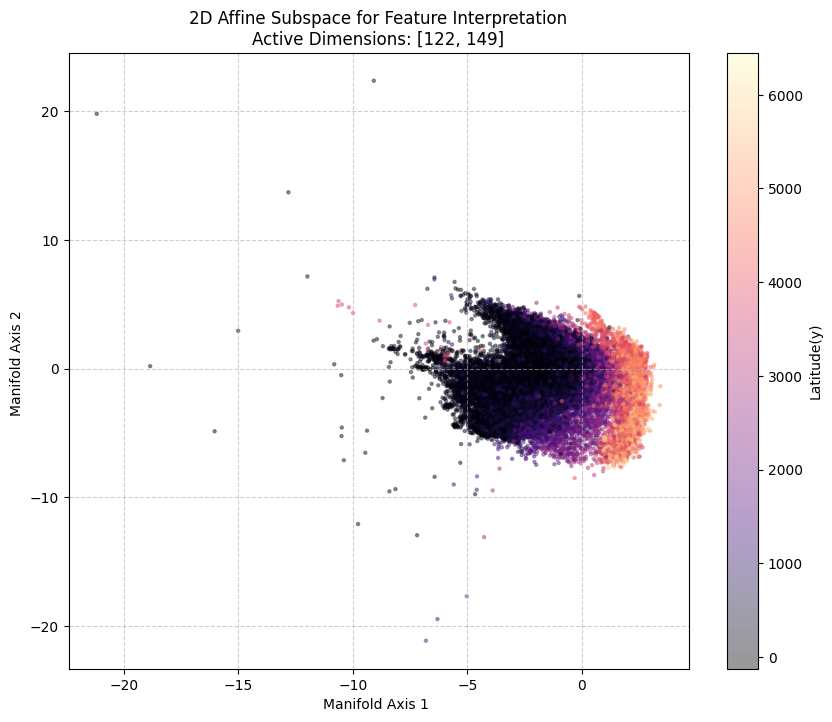

____________________________
/content/drive/MyDrive/terraLatents/latents_4_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 582.3750  99.5726  | 0.3394   | 0.0880   | 192/192
5      | 376.3302  88.6403  | 6.2579   | 5.1018   | 192/192
10     | 366.6714  87.8521  | 7.5073   | 4.6405   | 186/192
15     | 365.4937  87.0577  | 8.2921   | 4.6502   | 171/192
20     | 364.4379  86.7343  | 8.6246   | 4.6411   | 157/192
25     | 361.4095  87.0834  | 8.2317   | 4.6849   | 121/192
30     | 357.9210  87.5269  | 7.8564   | 4.6166   | 83/192
35     | 354.7213  88.0102  | 7.4066   | 4.5832   | 65/192
40     | 352.7440  88.4829  | 6.8279   | 4.6892   | 42/192
45     | 351.4956  88.8265  | 6.3565   | 4.8170   | 32/192
50     | 347.1992  89.0677  | 6.0559   | 4.8764   | 19/192
55     | 349.3046  89.0862  | 6.2395   | 4.6743   | 13/192
60     | 350.0696  89.4942  | 6.5171   | 3

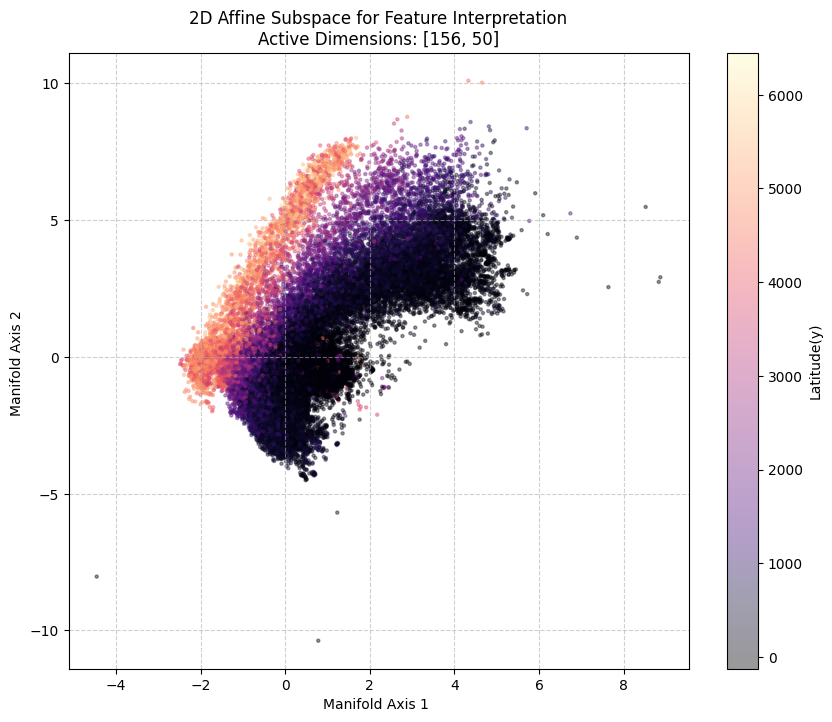

____________________________
/content/drive/MyDrive/terraLatents/latents_6_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 590.5808  99.5767  | 0.3350   | 0.0884   | 192/192
5      | 364.9120  87.4444  | 6.7207   | 5.8349   | 192/192
10     | 354.8717  86.3459  | 8.4495   | 5.2045   | 191/192
15     | 357.9750  85.0733  | 9.7930   | 5.1337   | 185/192
20     | 356.8183  83.9807  | 10.8424  | 5.1769   | 169/192
25     | 357.1607  83.9157  | 10.9225  | 5.1618   | 151/192
30     | 347.7243  84.5732  | 10.2824  | 5.1443   | 104/192
35     | 343.3015  85.7472  | 9.2032   | 5.0497   | 83/192
40     | 333.3873  87.4739  | 7.5357   | 4.9904   | 50/192
45     | 328.8374  88.7271  | 6.3960   | 4.8769   | 30/192
50     | 325.8421  89.1919  | 5.9329   | 4.8752   | 20/192
55     | 323.4124  89.8884  | 5.3024   | 4.8092   | 12/192
60     | 321.6612  90.5072  | 4.9063   | 

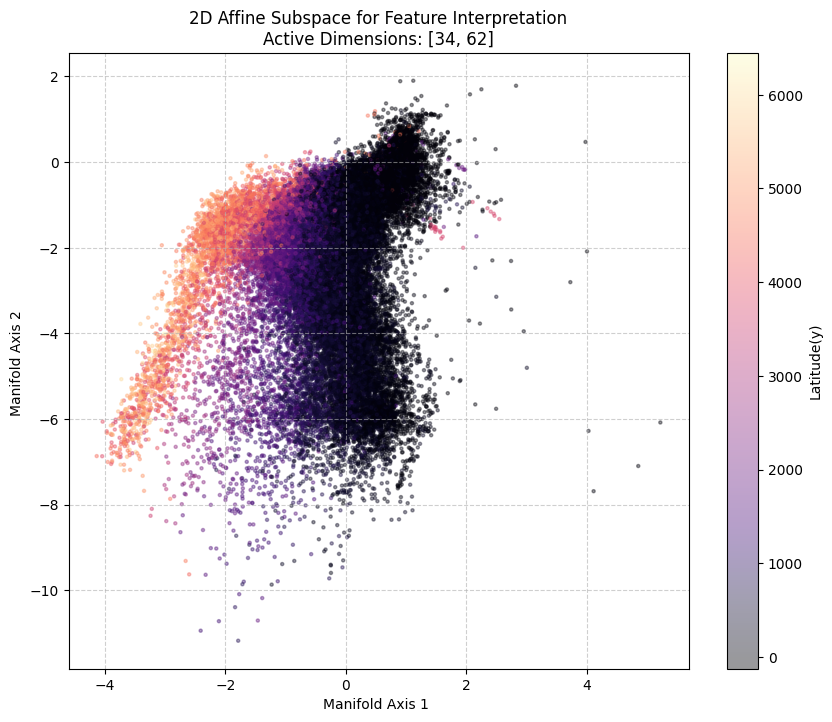

____________________________
/content/drive/MyDrive/terraLatents/latents_8_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 582.7839  99.5610  | 0.3392   | 0.0998   | 192/192
5      | 329.2805  87.1544  | 6.7248   | 6.1208   | 192/192
10     | 312.3969  84.8105  | 8.9897   | 6.1998   | 190/192
15     | 314.4600  83.2449  | 10.6042  | 6.1509   | 189/192
20     | 316.2544  82.2496  | 11.6252  | 6.1252   | 182/192
25     | 314.4347  82.0149  | 11.8057  | 6.1794   | 160/192
30     | 311.8257  82.5596  | 11.2697  | 6.1708   | 121/192
35     | 304.8615  83.8162  | 10.0742  | 6.1096   | 86/192
40     | 297.0520  85.3885  | 8.5095   | 6.1019   | 61/192
45     | 295.7502  86.5289  | 7.3513   | 6.1198   | 33/192
50     | 292.5851  86.9161  | 6.7312   | 6.3527   | 25/192
55     | 291.1774  87.3869  | 6.1429   | 6.4703   | 16/192
60     | 287.8231  88.0504  | 5.7427   | 

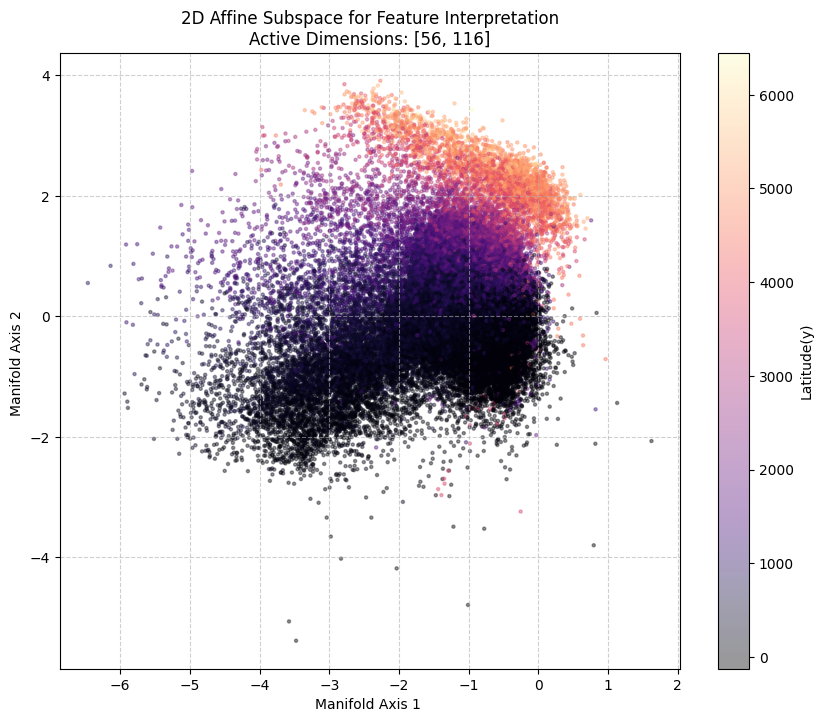

____________________________
/content/drive/MyDrive/terraLatents/latents_10_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 567.5349  99.5255  | 0.3526   | 0.1219   | 192/192
5      | 295.0451  87.4360  | 6.7831   | 5.7810   | 192/192
10     | 282.9915  84.9414  | 8.9981   | 6.0605   | 191/192
15     | 282.1414  82.8859  | 10.9434  | 6.1707   | 189/192
20     | 283.9384  81.2174  | 12.4870  | 6.2957   | 186/192
25     | 283.5734  80.4039  | 13.1225  | 6.4736   | 172/192
30     | 278.9063  80.3020  | 12.8990  | 6.7990   | 136/192
35     | 281.1486  81.4083  | 11.6830  | 6.9087   | 104/192
40     | 273.8944  82.1338  | 10.5753  | 7.2909   | 73/192
45     | 266.5545  82.9538  | 9.5028   | 7.5434   | 45/192
50     | 265.1733  83.6611  | 8.6621   | 7.6768   | 31/192
55     | 264.0910  84.0445  | 8.2400   | 7.7155   | 22/192
60     | 266.0554  84.2291  | 8.2555   

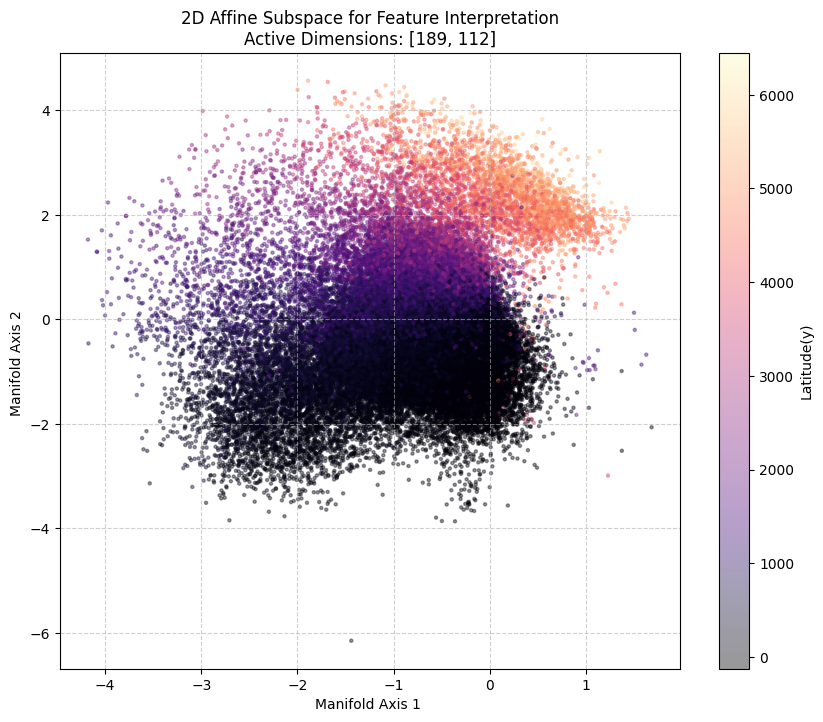

____________________________
/content/drive/MyDrive/terraLatents/latents_12_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 504.8420  98.7800  | 0.4175   | 0.8025   | 192/192
5      | 196.8997  88.4441  | 6.8544   | 4.7014   | 192/192
10     | 190.4001  86.6647  | 8.8869   | 4.4483   | 192/192
15     | 189.9644  85.0614  | 10.4417  | 4.4969   | 192/192
20     | 190.0148  84.0709  | 11.2732  | 4.6558   | 188/192
25     | 189.3563  83.8968  | 11.2325  | 4.8707   | 160/192
30     | 189.0482  83.9919  | 11.0822  | 4.9259   | 117/192
35     | 187.9410  83.9064  | 11.1244  | 4.9692   | 90/192
40     | 185.8560  84.3731  | 10.6000  | 5.0269   | 70/192
45     | 182.8298  85.4585  | 9.4198   | 5.1217   | 49/192
50     | 181.0887  85.8396  | 8.8192   | 5.3412   | 29/192
55     | 180.9375  85.8752  | 8.6341   | 5.4908   | 22/192
60     | 181.2028  85.9800  | 8.5188   |

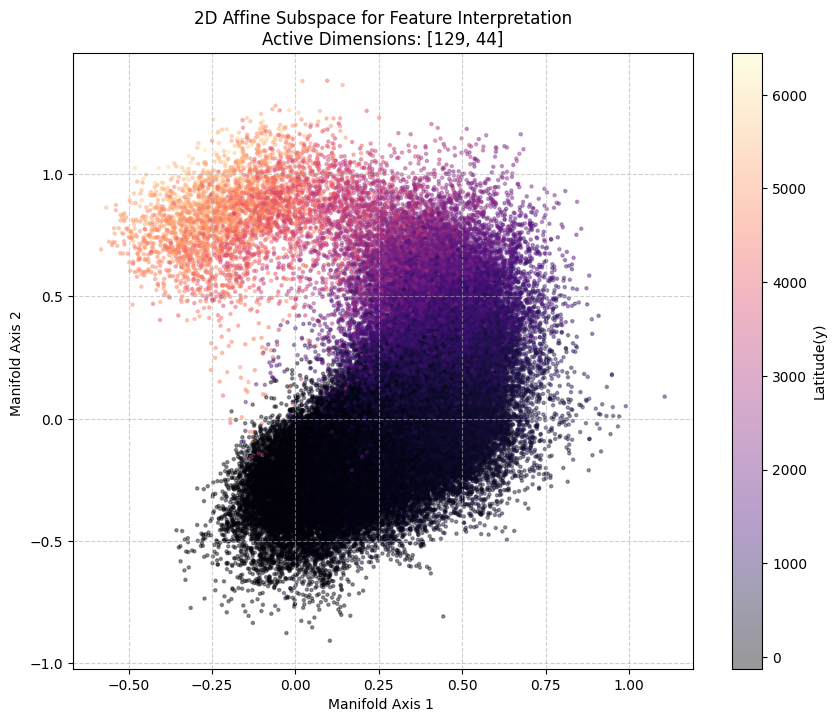

____________________________
Results saved to H_geometry_results.csv
____________________________
[Parameter containing:
tensor([[ 0.8607, -0.0414,  0.0138,  ..., -0.0164, -0.0599, -0.0689],
        [-0.0235,  0.9518, -0.0076,  ..., -0.0016, -0.0141, -0.0032],
        [-0.0207,  0.0068,  0.9629,  ..., -0.0012, -0.0201, -0.0144],
        ...,
        [ 0.0052,  0.0081, -0.0129,  ...,  0.9794, -0.0020, -0.0119],
        [ 0.0478, -0.0157,  0.0158,  ...,  0.0282,  0.8999,  0.0039],
        [ 0.0077, -0.0234,  0.0020,  ...,  0.0043, -0.0151,  0.9038]],
       device='cuda:0', requires_grad=True), Parameter containing:
tensor([[ 9.6435e-01,  2.1351e-02, -2.1438e-02,  ...,  2.0847e-02,
         -4.4249e-02,  2.5564e-02],
        [-6.4788e-03,  9.8039e-01, -1.8473e-03,  ..., -1.6463e-02,
          3.3668e-02, -2.0753e-04],
        [-1.4704e-02,  1.7123e-02,  9.8054e-01,  ...,  1.9040e-02,
         -2.1881e-02,  2.5127e-02],
        ...,
        [-6.2660e-03, -1.3115e-02,  2.6870e-04,  ...,  9

In [ ]:
import pandas as pd

idx = [2, 4, 6, 8, 10, 12]
R_mats = []
t_vecs = []
lambda_vecs = []
target_lambda = 2
epsilon = 1e-1

for id in idx:
  path = "/content/drive/MyDrive/terraLatents/latents_" + str(id) + "_92160_for_intervention.pt"
  print(path)
  data = torch.load(path, map_location=device)
  saved_latents = data["latents"]
  saved_meta = data["meta"]
  X = saved_latents
  y = saved_meta[:, 3]

  # --- Retry Mechanism for Lambda Count & Orthogonality ---
  count = 1
  while True:
      if id == 0:
        num_epochs = 40
        alpha = 1.35
      else:
        num_epochs = 150
        alpha = 1.35
      H_model, metrics = Geometry_Extraction(X, y, target_lambda=target_lambda, verbose=2, alpha_coeff = alpha ,beta_coeff = 1.45, n_epochs = num_epochs)

      # 1. Check Lambda count
      nonzero_count = torch.sum(H_model.lambda_vec.abs() > epsilon).item()

      # 2. Check Orthogonality: ||R^T * R - I||
      R = H_model.rotation_matrix
      RT_R = torch.matmul(R.t(), R)
      identity = torch.eye(R.size(1), device=R.device)
      ortho_error = torch.norm(RT_R - identity, p=2).item()

      if nonzero_count <= target_lambda and ortho_error < epsilon:
          break
      elif count > 3:
          print(f'RED FLAG for {path}')
          print(f"Final: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
      print(f"Retrying: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
  # -------------------------------------------------------

  H_model.eval()
  R_mats.append(H_model.rotation_matrix)
  t_vecs.append(H_model.t_vec)
  lambda_vecs.append(H_model.lambda_vec)
  with torch.no_grad():
      X_centered = X.to(device) + H_model.t_vec
      X_rotated = torch.matmul(X_centered, H_model.rotation_matrix)

      top_2_indices = torch.argsort(H_model.lambda_vec.abs(), descending=True)[:2]
      active_dims = X_rotated[:, top_2_indices].cpu().numpy()

      scales = H_model.lambda_vec[top_2_indices].cpu().numpy()
      print(f"Top 2 Lambda scales: {scales}")

  plt.figure(figsize=(10, 8))
  sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
               c=y.cpu().numpy(), cmap='magma', s=5, alpha=0.4)

  plt.xlabel(f"Manifold Axis 1 ")
  plt.ylabel(f"Manifold Axis 2 ")
  plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
  plt.colorbar(sc, label='Latitude(y)')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()
  print("_"*28)

# --- Save to CSV ---
results_df = pd.DataFrame({
    'idx': idx,
    'rotation_matrix': [r.cpu().tolist() for r in R_mats],
    'translation_vec': [t.cpu().tolist() for t in t_vecs],
    'lambda_vec': [l.cpu().tolist() for l in lambda_vecs]
})
results_df.to_csv("H_geometry_results.csv", index=False)
print("Results saved to H_geometry_results.csv")
print("_"*28)
print(R_mats)
print("_"*28)
print(t_vecs)
print("_"*28)
print(lambda_vecs)

/content/drive/MyDrive/terraLatents/latents_2_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 21.2512   90.9861  | 8.4957   | 0.5182   | 192/192
5      | 16.6295   92.7667  | 4.6861   | 2.5472   | 190/192
10     | 16.0596   93.5400  | 4.4168   | 2.0431   | 153/192
15     | 15.5595   94.3220  | 4.0332   | 1.6448   | 109/192
20     | 15.1678   94.7885  | 3.8897   | 1.3219   | 77/192
25     | 14.9387   95.3287  | 3.8373   | 0.8340   | 57/192
30     | 14.7604   95.7680  | 3.9555   | 0.2765   | 44/192
35     | 14.6726   95.5552  | 4.1564   | 0.2884   | 33/192
40     | 14.6304   95.2102  | 4.5309   | 0.2589   | 27/192
45     | 14.6466   94.8839  | 4.8632   | 0.2529   | 24/192
50     | 14.6213   94.6312  | 5.1544   | 0.2144   | 21/192
55     | 14.7783   94.3618  | 5.4219   | 0.2164   | 16/192
60     | 14.7191   94.0120  | 5.7920   | 0.1960   | 15/192
65     | 14.72

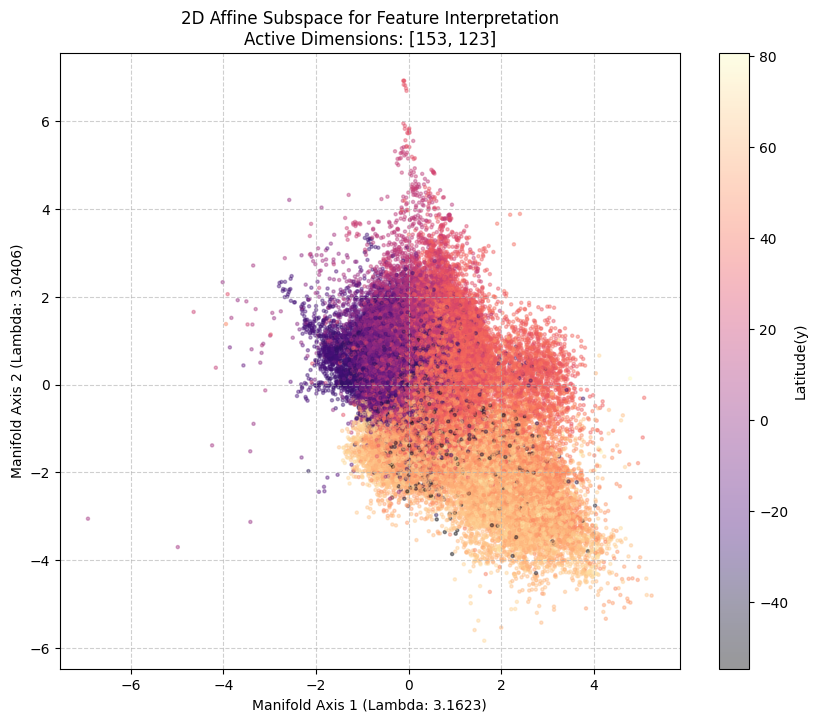

____________________________
/content/drive/MyDrive/terraLatents/latents_4_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 22.2120   91.3137  | 8.1145   | 0.5718   | 192/192
5      | 16.8474   92.8605  | 4.4407   | 2.6988   | 188/192
10     | 15.9316   93.1635  | 4.2222   | 2.6143   | 143/192
15     | 15.3595   93.8836  | 3.7451   | 2.3713   | 95/192
20     | 15.0030   94.5485  | 3.4813   | 1.9702   | 64/192
25     | 14.7071   94.7897  | 3.5776   | 1.6328   | 42/192
30     | 14.5231   94.9209  | 3.8607   | 1.2184   | 37/192
35     | 14.5433   95.3494  | 4.0578   | 0.5928   | 27/192
40     | 14.2979   95.2532  | 4.4887   | 0.2581   | 25/192
45     | 14.2717   94.9206  | 4.8240   | 0.2554   | 20/192
50     | 14.1120   94.6124  | 5.1594   | 0.2283   | 16/192
55     | 14.0649   94.4035  | 5.3691   | 0.2274   | 16/192
60     | 14.0466   94.3524  | 5.4185   | 0.22

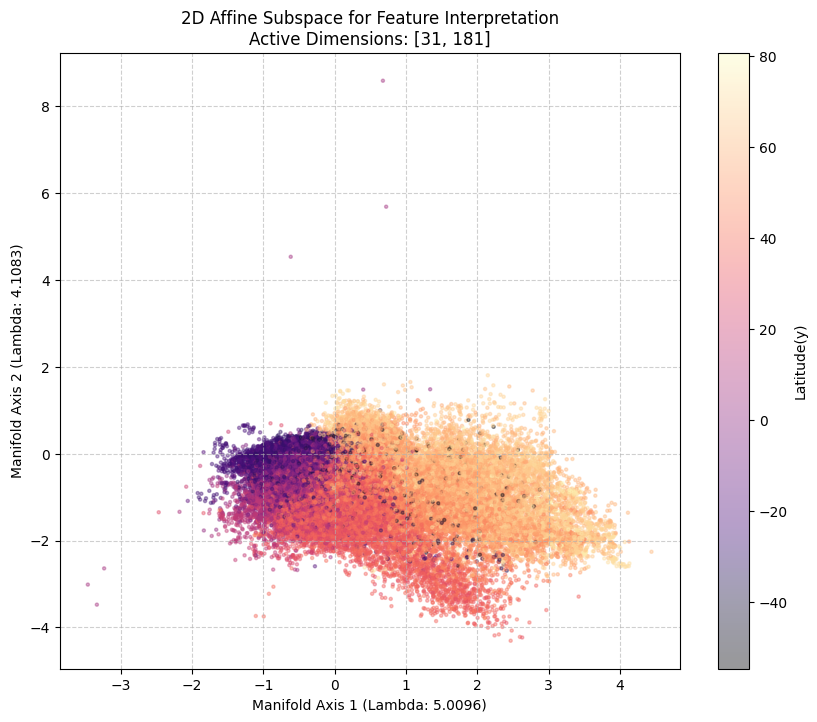

____________________________
/content/drive/MyDrive/terraLatents/latents_6_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 21.5661   91.1146  | 8.4100   | 0.4754   | 192/192
5      | 15.9327   91.8964  | 4.9100   | 3.1936   | 192/192
10     | 15.0146   91.9164  | 4.8687   | 3.2149   | 150/192
15     | 14.7430   92.3852  | 4.3888   | 3.2260   | 108/192
20     | 14.1193   92.5453  | 4.3306   | 3.1241   | 70/192
25     | 13.9852   92.6653  | 4.4387   | 2.8960   | 50/192
30     | 13.7784   92.7265  | 4.8049   | 2.4686   | 40/192
35     | 13.5613   93.0510  | 5.2788   | 1.6703   | 32/192
40     | 13.4970   93.8279  | 5.6825   | 0.4896   | 28/192
45     | 13.1862   93.4202  | 6.2191   | 0.3607   | 23/192
50     | 12.9368   92.8786  | 6.7700   | 0.3513   | 21/192
55     | 13.0960   92.5743  | 7.0602   | 0.3654   | 18/192
60     | 13.0324   92.2250  | 7.4507   | 0.3

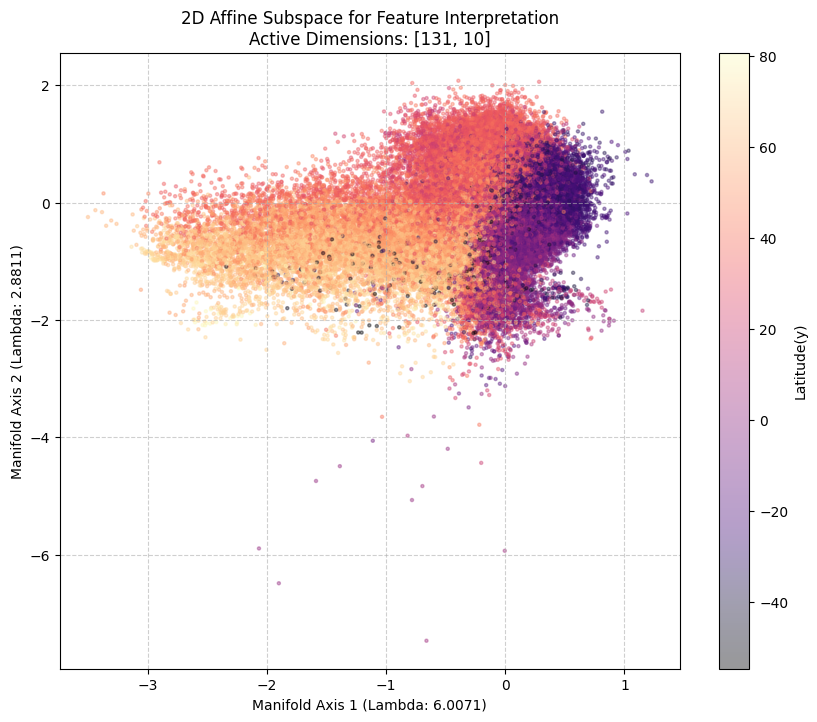

____________________________
/content/drive/MyDrive/terraLatents/latents_8_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 21.3876   90.8865  | 8.4905   | 0.6230   | 192/192
5      | 13.3495   89.6923  | 5.6124   | 4.6953   | 192/192
10     | 12.4319   88.0457  | 6.7032   | 5.2511   | 173/192
15     | 11.9867   87.3110  | 6.9963   | 5.6926   | 141/192
20     | 11.6086   87.0615  | 7.0093   | 5.9293   | 106/192
25     | 11.3479   87.1520  | 7.0698   | 5.7782   | 73/192
30     | 11.3523   87.5210  | 7.0869   | 5.3921   | 57/192
35     | 11.0501   87.7950  | 7.5691   | 4.6359   | 45/192
40     | 10.9741   89.0369  | 7.5400   | 3.4232   | 38/192
45     | 10.7453   90.6161  | 7.5270   | 1.8570   | 31/192
50     | 10.4323   92.2154  | 7.3542   | 0.4305   | 27/192
55     | 10.2702   92.6253  | 6.9631   | 0.4116   | 21/192
60     | 10.0755   92.8720  | 6.7619   | 0.

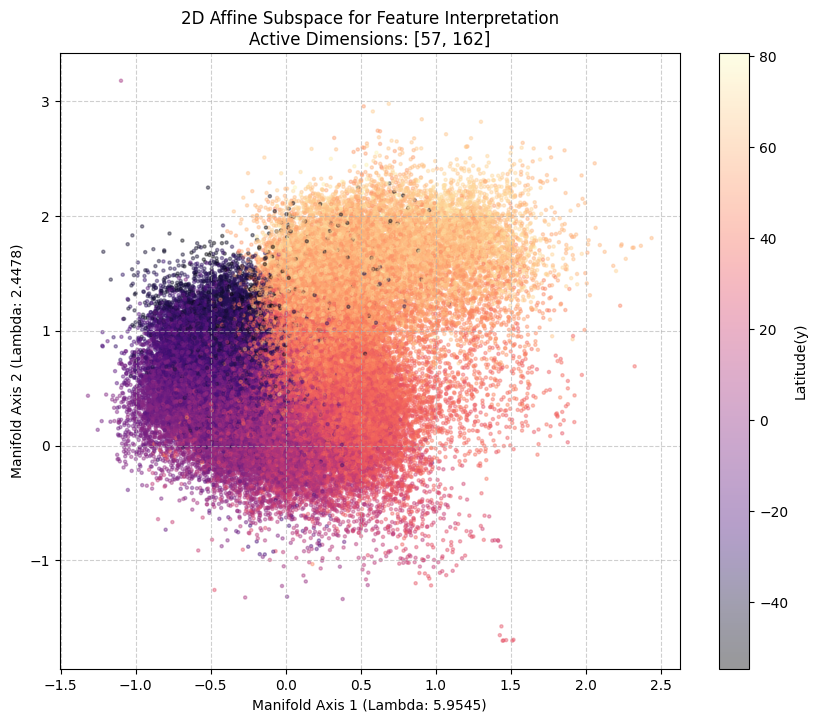

____________________________
/content/drive/MyDrive/terraLatents/latents_10_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 19.5074   89.9114  | 9.3516   | 0.7370   | 192/192
5      | 9.6777    86.7717  | 6.7799   | 6.4483   | 192/192
10     | 9.0904    83.9865  | 8.5391   | 7.4743   | 190/192
15     | 8.6251    82.3053  | 9.5867   | 8.1080   | 159/192
20     | 8.5248    82.0090  | 9.7221   | 8.2689   | 133/192
25     | 8.3066    82.7305  | 9.1566   | 8.1129   | 99/192
30     | 8.0819    83.5893  | 8.8367   | 7.5740   | 68/192
35     | 7.9581    84.7521  | 8.8556   | 6.3922   | 54/192
40     | 7.8665    86.3260  | 8.8556   | 4.8184   | 41/192
45     | 7.5591    88.0685  | 9.5092   | 2.4223   | 33/192
50     | 7.3492    89.4624  | 10.1701  | 0.3675   | 25/192
55     | 7.5195    89.7034  | 9.9353   | 0.3613   | 22/192
60     | 7.2538    89.7850  | 9.9181   | 0

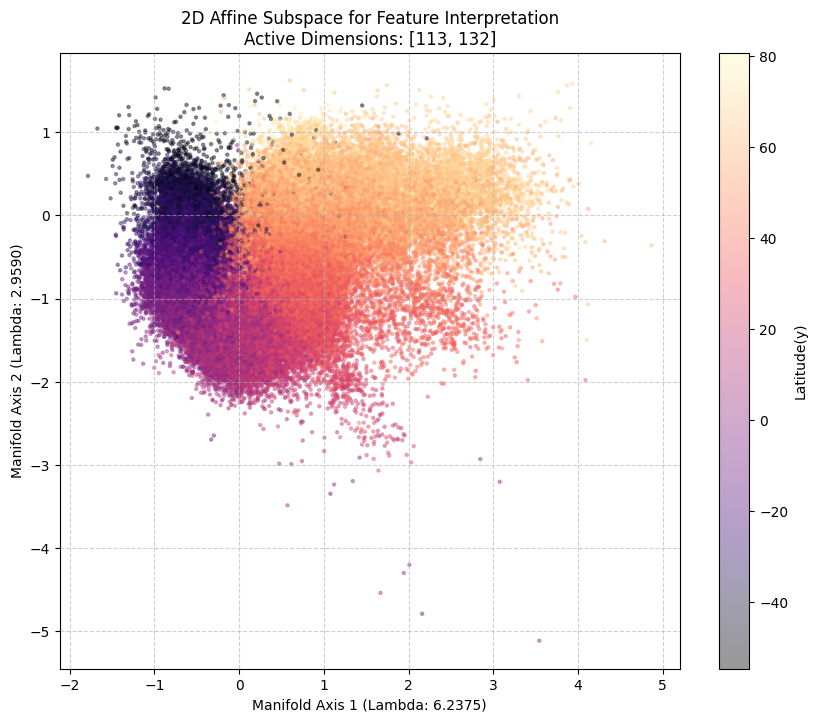

____________________________
/content/drive/MyDrive/terraLatents/latents_12_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 16.8112   83.2381  | 11.1596  | 5.6023   | 192/192
5      | 7.2067    88.6001  | 6.9197   | 4.4802   | 192/192
10     | 6.8487    86.2434  | 8.8588   | 4.8978   | 192/192
15     | 6.7195    85.1602  | 9.9512   | 4.8885   | 187/192
20     | 6.5850    85.2357  | 9.9345   | 4.8298   | 153/192
25     | 6.4060    86.0937  | 9.2246   | 4.6817   | 113/192
30     | 6.2650    86.9840  | 8.5816   | 4.4344   | 74/192
35     | 6.1419    87.8943  | 8.2877   | 3.8180   | 43/192
40     | 6.0884    88.3666  | 8.7637   | 2.8697   | 32/192
45     | 6.0128    89.1508  | 9.2120   | 1.6372   | 23/192
50     | 5.9364    89.8255  | 9.7670   | 0.4075   | 23/192
55     | 5.8797    89.7600  | 9.9968   | 0.2432   | 16/192
60     | 5.8352    89.4353  | 10.3785  | 

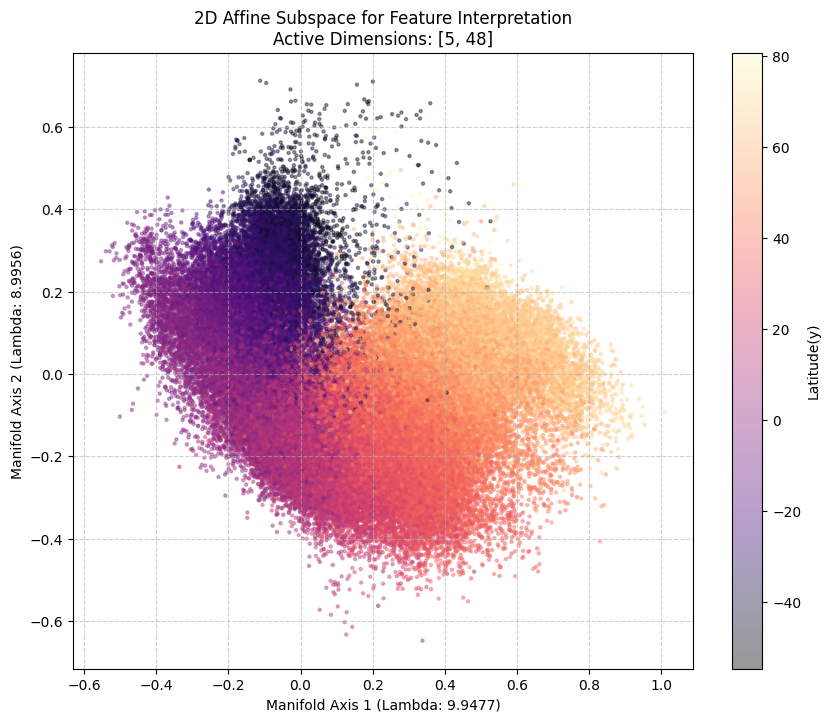

____________________________
Results saved to L_geometry_results.csv
____________________________
[Parameter containing:
tensor([[ 0.9425,  0.0048, -0.0123,  ..., -0.0465, -0.0373, -0.0351],
        [ 0.0022,  0.9717,  0.0062,  ...,  0.0268,  0.0256, -0.0058],
        [-0.0287, -0.0059,  0.9653,  ...,  0.0225, -0.0080, -0.0040],
        ...,
        [ 0.0178, -0.0229, -0.0248,  ...,  0.7213,  0.0359,  0.0065],
        [-0.0130,  0.0163,  0.0036,  ..., -0.0101,  0.8736,  0.0107],
        [-0.0062, -0.0174, -0.0048,  ..., -0.0095, -0.0309,  0.9396]],
       device='cuda:0', requires_grad=True), Parameter containing:
tensor([[ 0.9618, -0.0203, -0.0196,  ..., -0.0178, -0.0143,  0.0109],
        [ 0.0187,  0.9736, -0.0043,  ...,  0.0106,  0.0257,  0.0121],
        [-0.0267, -0.0035,  0.9730,  ..., -0.0041,  0.0047,  0.0077],
        ...,
        [ 0.0468,  0.0201,  0.0112,  ...,  0.6672, -0.0182, -0.0440],
        [-0.0333, -0.0081, -0.0284,  ..., -0.0243,  0.8781,  0.0077],
        [-0.036

In [ ]:
import pandas as pd

idx = [2, 4, 6, 8, 10, 12]
R_mats = []
t_vecs = []
lambda_vecs = []
target_lambda = 2
epsilon = 1e-1

for id in idx:
  path = "/content/drive/MyDrive/terraLatents/latents_" + str(id) + "_92160_for_intervention.pt"
  print(path)
  data = torch.load(path, map_location=device)
  saved_latents = data["latents"]
  saved_meta = data["meta"]
  X = saved_latents
  y = saved_meta[:, 0]

  # --- Retry Mechanism for Lambda Count & Orthogonality ---
  count = 1
  while True:
      H_model, metrics = Geometry_Extraction(X, y, target_lambda=target_lambda, verbose=2, beta_coeff=1.45, alpha_coeff=1.35, n_epochs = 150)

      # 1. Check Lambda count
      nonzero_count = torch.sum(H_model.lambda_vec.abs() > epsilon).item()

      # 2. Check Orthogonality: ||R^T * R - I||
      R = H_model.rotation_matrix
      RT_R = torch.matmul(R.t(), R)
      identity = torch.eye(R.size(1), device=R.device)
      ortho_error = torch.norm(RT_R - identity, p=2).item()

      if nonzero_count <= target_lambda and ortho_error < epsilon:
          break
      elif count > 3:
          print(f'RED FLAG for {path}')
          print(f"Final: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
      print(f"Retrying: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
  # -------------------------------------------------------

  H_model.eval()
  R_mats.append(H_model.rotation_matrix)
  t_vecs.append(H_model.t_vec)
  lambda_vecs.append(H_model.lambda_vec)
  with torch.no_grad():
      X_centered = X.to(device) + H_model.t_vec
      X_rotated = torch.matmul(X_centered, H_model.rotation_matrix)

      top_2_indices = torch.argsort(H_model.lambda_vec.abs(), descending=True)[:2]
      active_dims = X_rotated[:, top_2_indices].cpu().numpy()

      scales = H_model.lambda_vec[top_2_indices].cpu().numpy()
      print(f"Top 2 Lambda scales: {scales}")

  plt.figure(figsize=(10, 8))
  sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
               c=y.cpu().numpy(), cmap='magma', s=5, alpha=0.4)

  plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
  plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
  plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
  plt.colorbar(sc, label='Latitude(y)')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()
  print("_"*28)

# --- Save to CSV ---
results_df = pd.DataFrame({
    'idx': idx,
    'rotation_matrix': [r.cpu().tolist() for r in R_mats],
    'translation_vec': [t.cpu().tolist() for t in t_vecs],
    'lambda_vec': [l.cpu().tolist() for l in lambda_vecs]
})
results_df.to_csv("L_geometry_results.csv", index=False)
print("Results saved to L_geometry_results.csv")
print("_"*28)
print(R_mats)
print("_"*28)
print(t_vecs)
print("_"*28)
print(lambda_vecs)

/content/drive/MyDrive/terraLatents/latents_2_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.2482    25.4030  | 74.2401  | 0.3569   | 192/192
5      | 0.5853    87.7297  | 9.7526   | 2.5178   | 192/192
10     | 0.5391    92.5146  | 4.9311   | 2.5543   | 120/192
15     | 0.5166    94.5437  | 3.1535   | 2.3029   | 48/192
20     | 0.5077    94.9121  | 2.8796   | 2.2083   | 31/192
25     | 0.5018    94.9168  | 3.0009   | 2.0823   | 23/192
30     | 0.4996    94.7607  | 3.2369   | 2.0024   | 21/192
35     | 0.4986    94.5518  | 3.4317   | 2.0165   | 18/192
40     | 0.4984    94.3301  | 3.6979   | 1.9720   | 18/192
45     | 0.4983    94.1678  | 3.9422   | 1.8900   | 17/192
50     | 0.4989    93.9137  | 4.1921   | 1.8943   | 16/192
55     | 0.4999    93.6489  | 4.5528   | 1.7983   | 16/192
60     | 0.5020    93.4306  | 4.8304   | 1.7390   | 15/192
65     | 0.5035

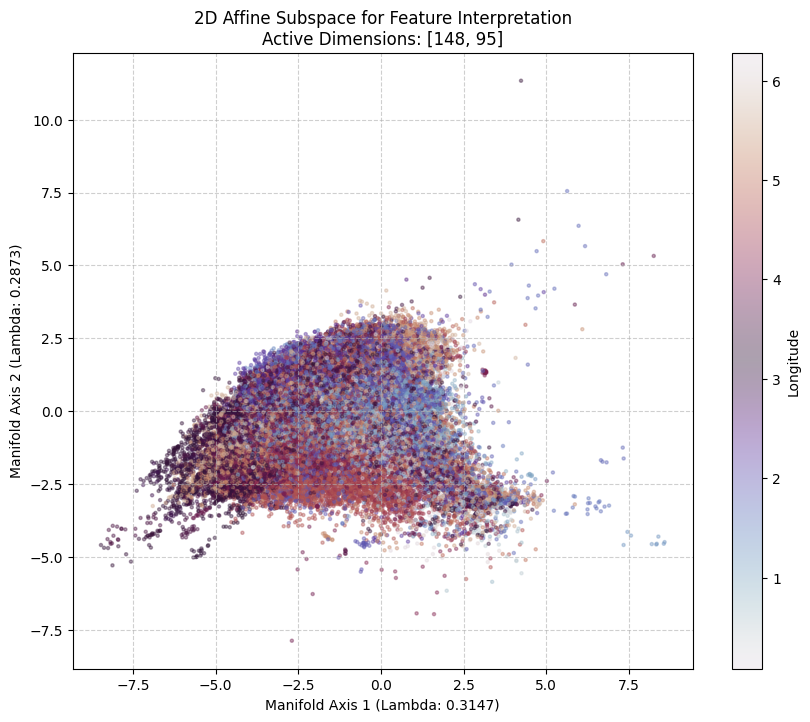

____________________________
/content/drive/MyDrive/terraLatents/latents_4_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.2392    25.2802  | 74.3586  | 0.3611   | 192/192
5      | 0.5737    87.7870  | 9.8283   | 2.3846   | 192/192
10     | 0.5153    93.4115  | 4.3484   | 2.2401   | 92/192
15     | 0.4952    94.8150  | 3.0830   | 2.1020   | 35/192
20     | 0.4893    94.6407  | 3.2333   | 2.1260   | 28/192
25     | 0.4847    94.5228  | 3.4498   | 2.0273   | 24/192
30     | 0.4834    94.2432  | 3.6866   | 2.0701   | 22/192
35     | 0.4818    93.9795  | 3.9525   | 2.0680   | 21/192
40     | 0.4801    93.8540  | 4.1986   | 1.9474   | 20/192
45     | 0.4815    93.5701  | 4.4620   | 1.9679   | 18/192
50     | 0.4805    93.4083  | 4.7813   | 1.8104   | 18/192
55     | 0.4826    93.1761  | 5.0819   | 1.7421   | 17/192
60     | 0.4849    92.8081  | 5.4116   | 1.780

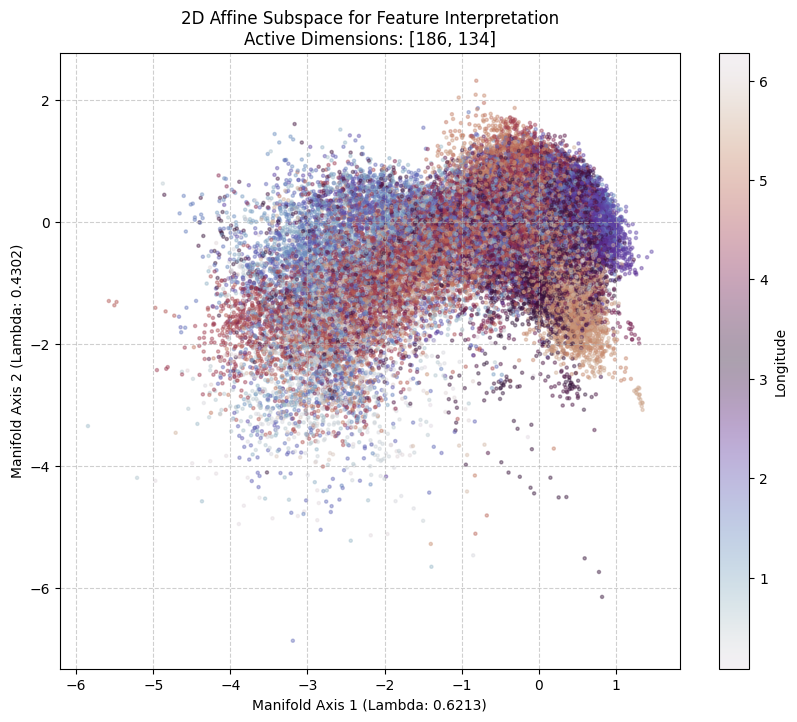

____________________________
/content/drive/MyDrive/terraLatents/latents_6_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.2423    25.3770  | 74.2492  | 0.3738   | 192/192
5      | 0.5670    88.4176  | 10.0266  | 1.5558   | 192/192
10     | 0.5076    94.0195  | 4.5344   | 1.4461   | 84/192
15     | 0.4874    95.4710  | 3.1129   | 1.4161   | 36/192
20     | 0.4789    95.2647  | 3.2812   | 1.4541   | 26/192
25     | 0.4748    94.9471  | 3.5406   | 1.5123   | 23/192
30     | 0.4706    94.7873  | 3.7974   | 1.4153   | 22/192
35     | 0.4689    94.5089  | 3.9925   | 1.4986   | 21/192
40     | 0.4699    94.1036  | 4.2617   | 1.6346   | 20/192
45     | 0.4673    94.0669  | 4.5633   | 1.3698   | 19/192
50     | 0.4675    93.7913  | 4.8489   | 1.3598   | 19/192
55     | 0.4683    93.5029  | 5.1924   | 1.3047   | 18/192
60     | 0.4693    93.2355  | 5.5280   | 1.236

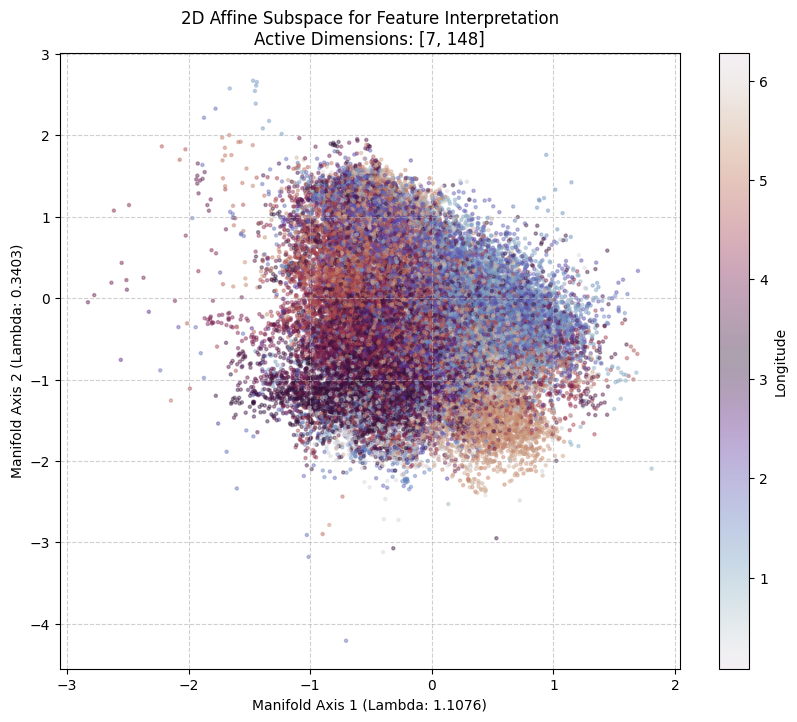

____________________________
/content/drive/MyDrive/terraLatents/latents_8_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.2252    24.9975  | 74.6202  | 0.3823   | 192/192
5      | 0.5421    87.4975  | 10.8444  | 1.6581   | 192/192
10     | 0.4922    91.4507  | 7.1045   | 1.4448   | 126/192
15     | 0.4630    93.7899  | 4.7959   | 1.4141   | 59/192
20     | 0.4492    94.0206  | 4.3969   | 1.5824   | 36/192
25     | 0.4406    93.7443  | 4.7523   | 1.5033   | 29/192
30     | 0.4346    93.3325  | 5.2159   | 1.4516   | 25/192
35     | 0.4325    92.9546  | 5.5838   | 1.4615   | 25/192
40     | 0.4321    92.6466  | 5.8530   | 1.5004   | 24/192
45     | 0.4294    92.4271  | 6.1924   | 1.3805   | 22/192
50     | 0.4297    92.1260  | 6.4704   | 1.4035   | 21/192
55     | 0.4321    91.8189  | 6.7633   | 1.4177   | 21/192
60     | 0.4316    91.4565  | 7.2284   | 1.31

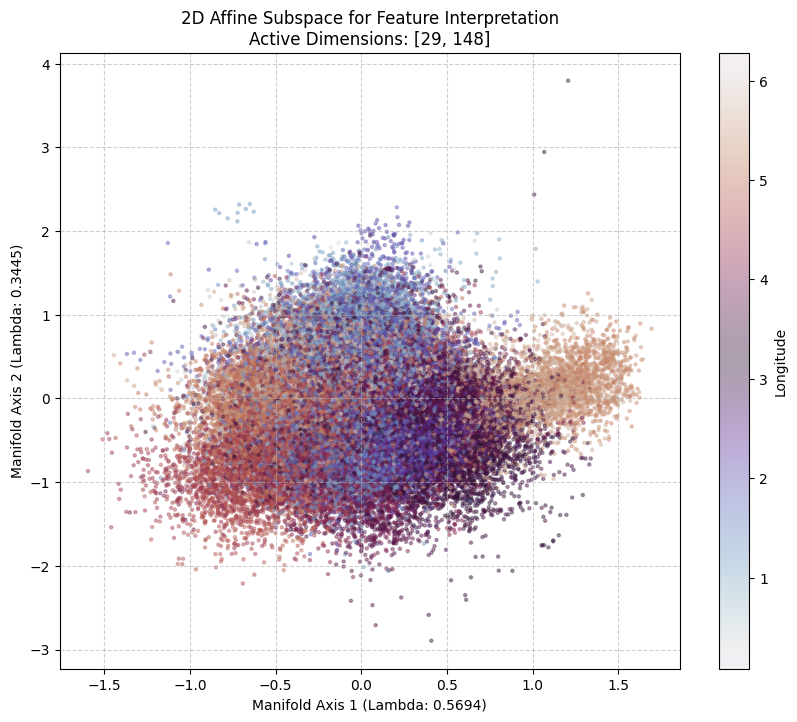

____________________________
/content/drive/MyDrive/terraLatents/latents_10_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.2108    24.1916  | 75.3358  | 0.4727   | 192/192
5      | 0.4926    86.1704  | 12.7287  | 1.1009   | 192/192
10     | 0.4393    87.0372  | 11.8862  | 1.0766   | 165/192
15     | 0.3973    90.9978  | 7.9877   | 1.0146   | 88/192
20     | 0.3709    92.7958  | 6.1938   | 1.0104   | 51/192
25     | 0.3552    92.7827  | 6.1378   | 1.0795   | 42/192
30     | 0.3466    92.5690  | 6.3495   | 1.0815   | 38/192
35     | 0.3409    92.2323  | 6.6570   | 1.1107   | 35/192
40     | 0.3404    92.0114  | 6.8072   | 1.1815   | 32/192
45     | 0.3378    91.5781  | 7.2654   | 1.1564   | 27/192
50     | 0.3342    91.2301  | 7.6487   | 1.1212   | 25/192
55     | 0.3372    91.0237  | 7.9017   | 1.0746   | 23/192
60     | 0.3381    90.5846  | 8.2998   | 1.1

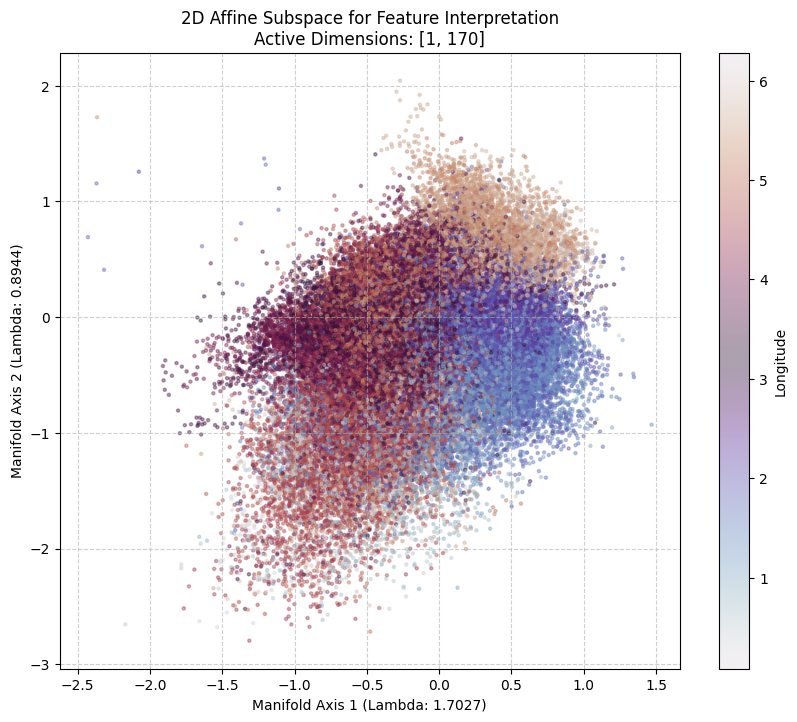

____________________________
/content/drive/MyDrive/terraLatents/latents_12_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.0464    19.5116  | 79.6410  | 0.8475   | 192/192
5      | 0.3400    82.2895  | 14.9306  | 2.7799   | 192/192
10     | 0.3007    87.9944  | 9.8624   | 2.1432   | 138/192
15     | 0.2770    90.7894  | 7.6929   | 1.5177   | 70/192
20     | 0.2657    91.0731  | 7.6830   | 1.2440   | 52/192
25     | 0.2616    90.7431  | 8.1108   | 1.1461   | 44/192
30     | 0.2600    90.2082  | 8.7095   | 1.0824   | 40/192
35     | 0.2598    89.6880  | 9.3268   | 0.9851   | 35/192
40     | 0.2610    89.0987  | 9.9666   | 0.9347   | 34/192
45     | 0.2630    88.5599  | 10.5364  | 0.9037   | 31/192
50     | 0.2657    87.9223  | 11.2178  | 0.8599   | 28/192
55     | 0.2690    87.3182  | 11.8569  | 0.8249   | 27/192
60     | 0.2728    86.7581  | 12.4359  | 0.8

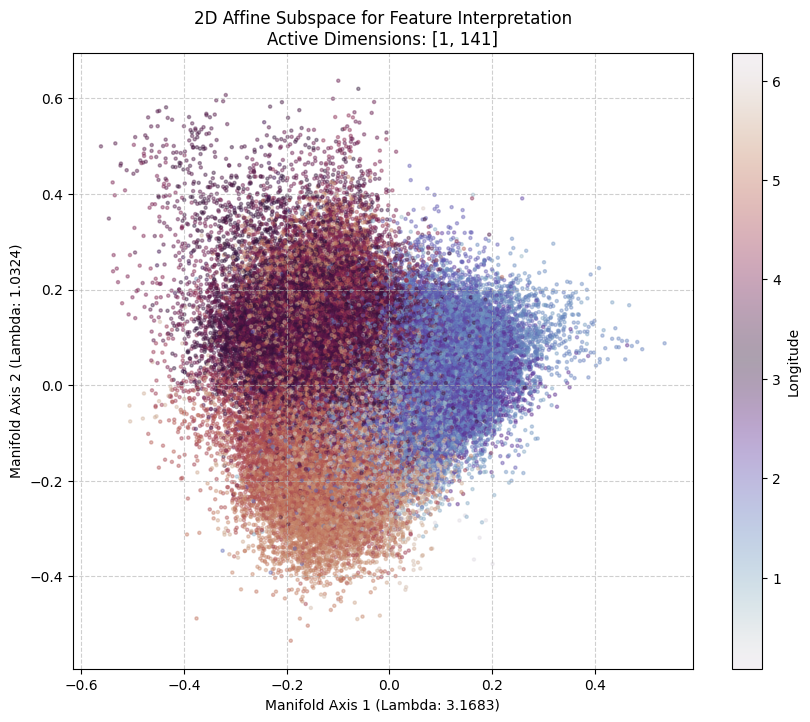

____________________________
Results saved to Long_geometry_results.csv
____________________________
[Parameter containing:
tensor([[ 9.2145e-01, -8.5992e-03, -2.1575e-02,  ..., -1.0056e-02,
         -4.2380e-02, -1.4894e-02],
        [ 8.2688e-03,  9.8240e-01,  3.7683e-03,  ..., -7.9771e-03,
         -3.0594e-03, -5.7453e-03],
        [ 5.7511e-03,  4.0542e-03,  9.8189e-01,  ..., -5.7297e-03,
          8.5709e-04, -5.8647e-03],
        ...,
        [-2.0099e-03, -5.5111e-03, -1.9355e-02,  ...,  9.1840e-01,
         -9.5449e-03, -8.1898e-03],
        [-3.8225e-02,  5.3999e-03, -1.0022e-02,  ..., -1.6703e-03,
          9.1903e-01,  6.8837e-03],
        [-3.0784e-02, -1.7651e-02,  6.8068e-03,  ..., -1.6173e-03,
          6.0444e-03,  9.4817e-01]], device='cuda:0', requires_grad=True), Parameter containing:
tensor([[ 9.2982e-01,  1.6938e-02, -2.6170e-02,  ...,  4.1396e-02,
         -1.0036e-02,  3.2743e-03],
        [-8.7340e-03,  9.8623e-01,  2.8039e-03,  ...,  2.1801e-02,
          7.79

In [ ]:
import pandas as pd

idx = [2, 4, 6, 8, 10, 12]
R_mats = []
t_vecs = []
lambda_vecs = []
target_lambda = 2
epsilon = 1e-1

for id in idx:
  path = "/content/drive/MyDrive/terraLatents/latents_" + str(id) + "_92160_for_intervention.pt"
  print(path)
  data = torch.load(path, map_location=device)
  saved_latents = data["latents"]
  saved_meta = data["meta"]
  X = saved_latents
  longs = np.pi * (saved_meta[:, 1] + 180) / 180
  sins = torch.sin(longs)
  coss = torch.cos(longs)
  y = torch.stack([sins, coss], dim=1)

  # --- Retry Mechanism for Lambda Count & Orthogonality ---
  count = 1
  while True:
      H_model, metrics = Geometry_Extraction(X, y, target_lambda=target_lambda, verbose=2, out_dim = 2, beta_coeff=1.45, alpha_coeff=1.4, n_epochs = 150)

      # 1. Check Lambda count
      nonzero_count = torch.sum(H_model.lambda_vec.abs() > epsilon).item()

      # 2. Check Orthogonality: ||R^T * R - I||
      R = H_model.rotation_matrix
      RT_R = torch.matmul(R.t(), R)
      identity = torch.eye(R.size(1), device=R.device)
      ortho_error = torch.norm(RT_R - identity, p=2).item()

      if nonzero_count <= target_lambda and ortho_error < epsilon:
          break
      elif count > 3:
          print(f'RED FLAG for {path}')
          print(f"Final: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
      print(f"Retrying: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
  # -------------------------------------------------------

  H_model.eval()
  R_mats.append(H_model.rotation_matrix)
  t_vecs.append(H_model.t_vec)
  lambda_vecs.append(H_model.lambda_vec)
  with torch.no_grad():
      X_centered = X.to(device) + H_model.t_vec
      X_rotated = torch.matmul(X_centered, H_model.rotation_matrix)

      top_2_indices = torch.argsort(H_model.lambda_vec.abs(), descending=True)[:2]
      active_dims = X_rotated[:, top_2_indices].cpu().numpy()

      scales = H_model.lambda_vec[top_2_indices].cpu().numpy()
      print(f"Top 2 Lambda scales: {scales}")

  plt.figure(figsize=(10, 8))
  sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
               c=longs.cpu().numpy(), cmap='twilight', s=5, alpha=0.4)

  plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
  plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
  plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
  plt.colorbar(sc, label='Longitude')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()
  print("_"*28)

# --- Save to CSV ---
results_df = pd.DataFrame({
    'idx': idx,
    'rotation_matrix': [r.cpu().tolist() for r in R_mats],
    'translation_vec': [t.cpu().tolist() for t in t_vecs],
    'lambda_vec': [l.cpu().tolist() for l in lambda_vecs]
})
results_df.to_csv("Long_geometry_results.csv", index=False)
print("Results saved to Long_geometry_results.csv")
print("_"*28)
print(R_mats)
print("_"*28)
print(t_vecs)
print("_"*28)
print(lambda_vecs)

/content/drive/MyDrive/terraLatents/latents_2_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.3427    23.6229  | 76.0384  | 0.3388   | 192/192
5      | 0.5947    80.9421  | 17.4875  | 1.5704   | 192/192
10     | 0.5874    78.8546  | 19.4139  | 1.7315   | 192/192
15     | 0.5595    81.5347  | 16.8111  | 1.6542   | 192/192
20     | 0.5131    88.2807  | 10.2046  | 1.5147   | 94/192
25     | 0.4929    91.2676  | 7.1866   | 1.5458   | 54/192
30     | 0.4782    92.8024  | 5.8889   | 1.3087   | 32/192
35     | 0.4763    93.1794  | 5.3771   | 1.4435   | 23/192
40     | 0.4719    93.3396  | 5.3348   | 1.3257   | 22/192
45     | 0.4706    93.3670  | 5.2211   | 1.4119   | 18/192
50     | 0.4669    93.3080  | 5.4791   | 1.2129   | 18/192
55     | 0.4671    93.1034  | 5.6466   | 1.2499   | 18/192
60     | 0.4673    92.9861  | 5.7960   | 1.2179   | 18/192
65     | 0.467

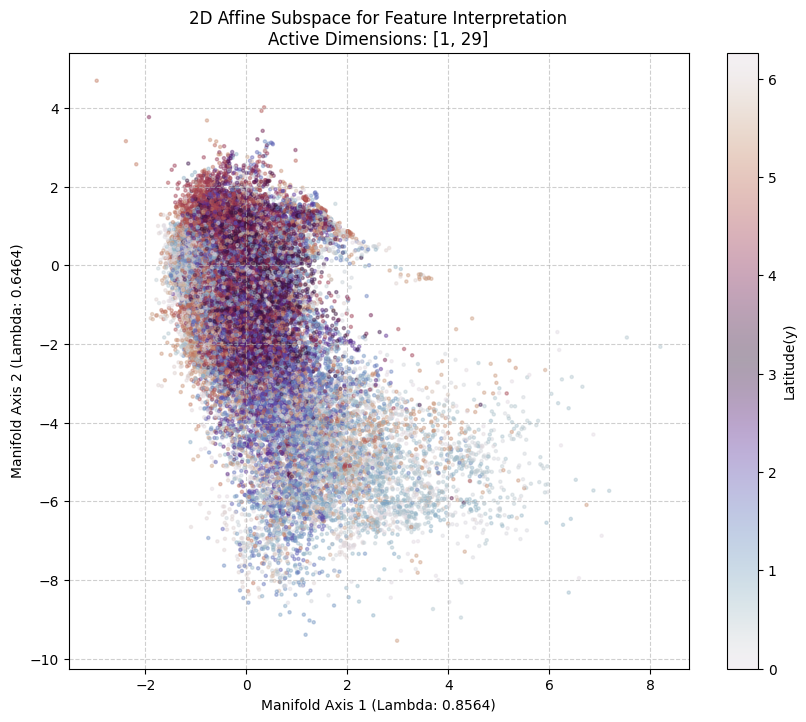

____________________________
/content/drive/MyDrive/terraLatents/latents_4_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.3420    23.6744  | 75.9770  | 0.3487   | 192/192
5      | 0.5996    81.4010  | 17.4195  | 1.1796   | 192/192
10     | 0.5898    79.1059  | 19.5906  | 1.3035   | 192/192
15     | 0.5574    81.3453  | 17.3854  | 1.2693   | 190/192
20     | 0.5147    86.9157  | 11.8459  | 1.2384   | 98/192
25     | 0.4915    89.8170  | 9.0403   | 1.1426   | 56/192
30     | 0.4823    91.1139  | 7.6094   | 1.2767   | 37/192
35     | 0.4724    92.0768  | 6.6734   | 1.2497   | 28/192
40     | 0.4635    92.7172  | 6.1458   | 1.1369   | 23/192
45     | 0.4607    93.0001  | 5.8875   | 1.1124   | 22/192
50     | 0.4614    92.9885  | 5.8049   | 1.2067   | 21/192
55     | 0.4606    92.9310  | 5.8568   | 1.2121   | 19/192
60     | 0.4636    92.5163  | 6.0901   | 1.3

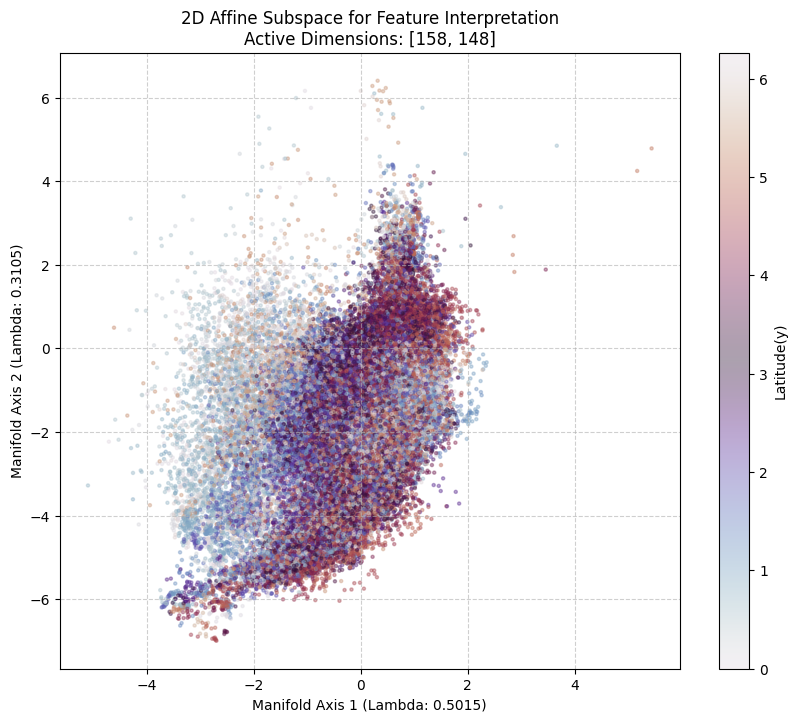

____________________________
/content/drive/MyDrive/terraLatents/latents_6_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.3591    24.1290  | 75.4864  | 0.3846   | 192/192
5      | 0.5959    81.4086  | 17.4989  | 1.0926   | 192/192
10     | 0.5898    79.0742  | 19.6392  | 1.2866   | 192/192
15     | 0.5511    80.8567  | 17.7990  | 1.3443   | 189/192
20     | 0.5031    86.5632  | 12.2815  | 1.1553   | 99/192
25     | 0.4799    89.7768  | 9.0764   | 1.1469   | 56/192
30     | 0.4683    90.8264  | 7.9944   | 1.1792   | 36/192
35     | 0.4589    91.2359  | 7.6273   | 1.1368   | 32/192
40     | 0.4590    91.5011  | 7.2221   | 1.2768   | 29/192
45     | 0.4515    91.8009  | 7.0898   | 1.1093   | 26/192
50     | 0.4496    91.8478  | 6.9782   | 1.1740   | 25/192
55     | 0.4469    91.8864  | 6.9616   | 1.1520   | 24/192
60     | 0.4475    91.8981  | 6.9321   | 1.1

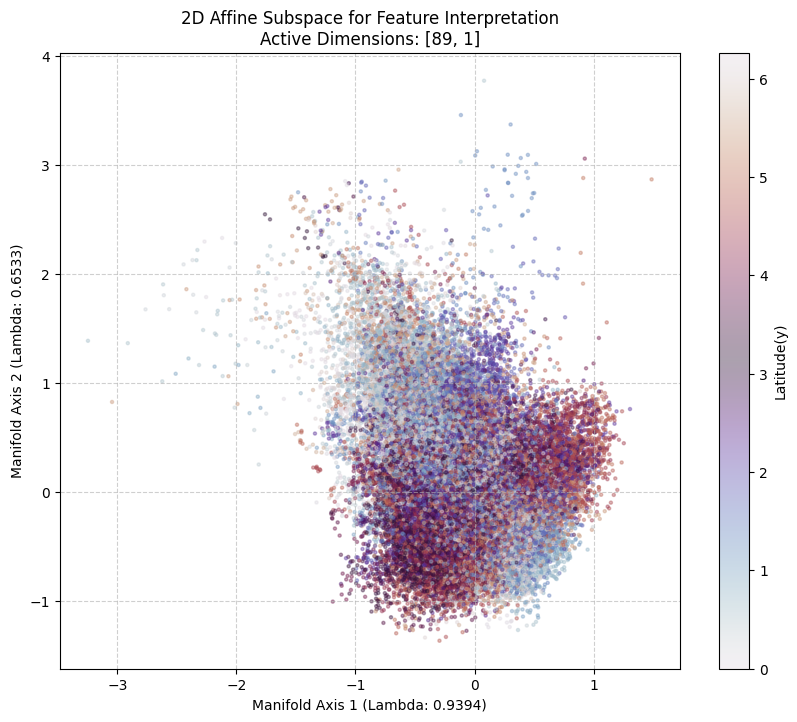

____________________________
/content/drive/MyDrive/terraLatents/latents_8_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.3419    23.6394  | 76.0081  | 0.3525   | 192/192
5      | 0.5669    80.5074  | 18.5421  | 0.9505   | 192/192
10     | 0.5497    76.5143  | 22.5960  | 0.8897   | 192/192
15     | 0.5382    75.1725  | 23.9617  | 0.8659   | 191/192
20     | 0.5065    77.2941  | 21.8593  | 0.8465   | 144/192
25     | 0.4710    81.2644  | 17.8914  | 0.8442   | 101/192
30     | 0.4353    86.5048  | 12.7341  | 0.7611   | 56/192
35     | 0.4201    89.1140  | 10.0712  | 0.8148   | 40/192
40     | 0.4068    90.7268  | 8.4758   | 0.7974   | 31/192
45     | 0.4007    91.6001  | 7.5700   | 0.8299   | 23/192
50     | 0.3939    92.0813  | 7.1816   | 0.7370   | 20/192
55     | 0.3931    92.2857  | 6.9032   | 0.8111   | 19/192
60     | 0.3897    92.3495  | 6.8751   | 0

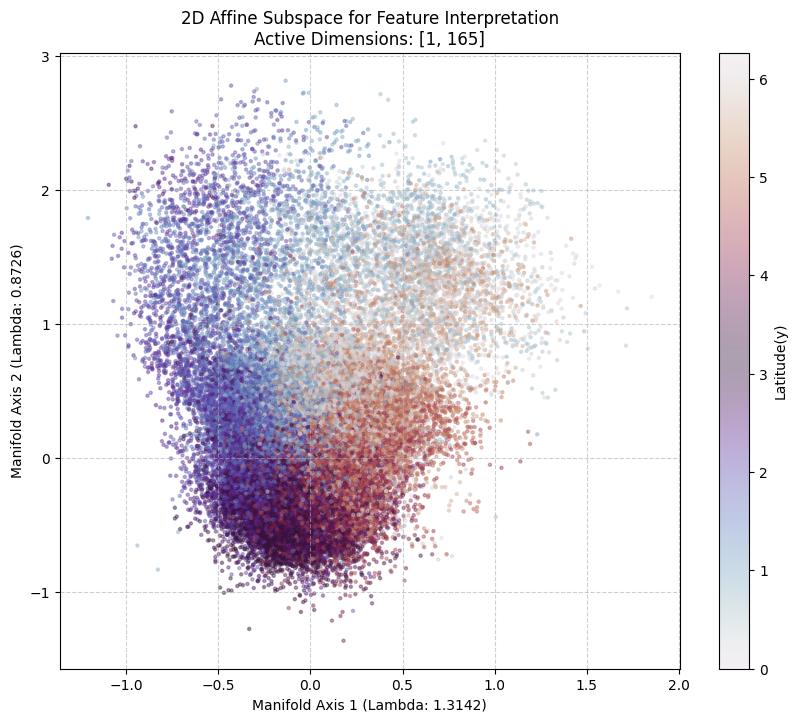

____________________________
/content/drive/MyDrive/terraLatents/latents_10_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.3316    23.0544  | 76.5110  | 0.4346   | 192/192
5      | 0.5068    78.5736  | 20.6524  | 0.7740   | 192/192
10     | 0.4975    73.8325  | 25.3687  | 0.7988   | 192/192
15     | 0.4909    71.2308  | 27.9280  | 0.8412   | 192/192
20     | 0.4660    72.4295  | 26.8255  | 0.7449   | 160/192
25     | 0.4337    77.7086  | 21.5043  | 0.7871   | 113/192
30     | 0.3913    84.5274  | 14.8236  | 0.6490   | 61/192
35     | 0.3708    88.0719  | 11.3211  | 0.6070   | 42/192
40     | 0.3649    89.7722  | 9.6153   | 0.6125   | 32/192
45     | 0.3549    90.2372  | 9.1708   | 0.5920   | 27/192
50     | 0.3541    90.5458  | 8.7819   | 0.6723   | 25/192
55     | 0.3511    90.7515  | 8.6594   | 0.5890   | 23/192
60     | 0.3495    90.6808  | 8.6909   | 

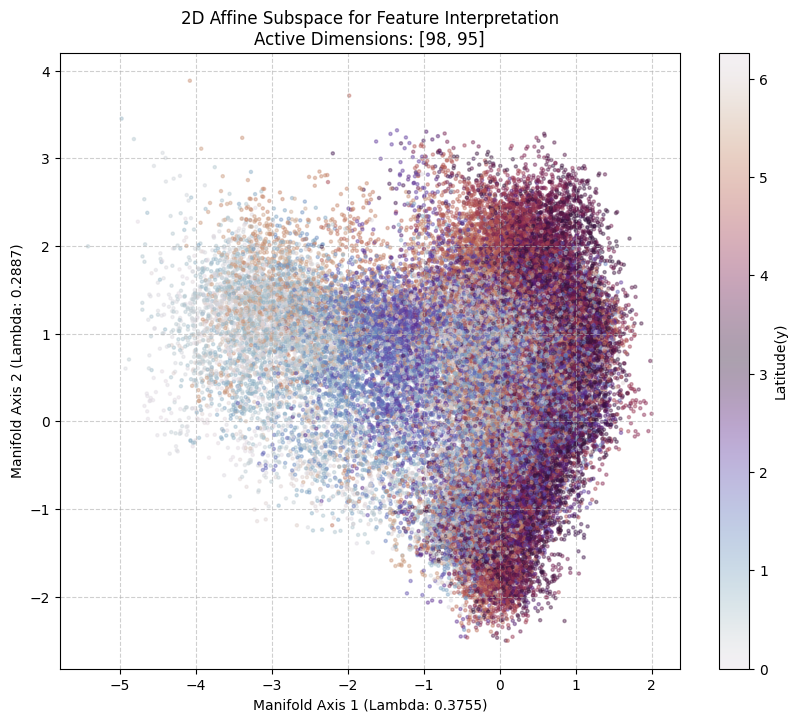

____________________________
/content/drive/MyDrive/terraLatents/latents_12_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.1964    19.3179  | 79.7726  | 0.9096   | 192/192
5      | 0.4215    75.1763  | 22.1919  | 2.6318   | 192/192
10     | 0.4045    72.7566  | 24.7851  | 2.4583   | 192/192
15     | 0.3727    76.8127  | 21.0511  | 2.1362   | 192/192
20     | 0.3360    85.6317  | 12.7803  | 1.5879   | 104/192
25     | 0.3221    88.2597  | 10.3027  | 1.4376   | 59/192
30     | 0.3158    88.7484  | 10.0266  | 1.2250   | 47/192
35     | 0.3115    88.6655  | 10.3246  | 1.0099   | 38/192
40     | 0.3102    88.4542  | 10.5656  | 0.9801   | 34/192
45     | 0.3108    88.2251  | 10.8036  | 0.9713   | 31/192
50     | 0.3113    88.0039  | 11.1456  | 0.8505   | 26/192
55     | 0.3126    87.6852  | 11.5138  | 0.8010   | 25/192
60     | 0.3153    87.3898  | 11.8511  | 0

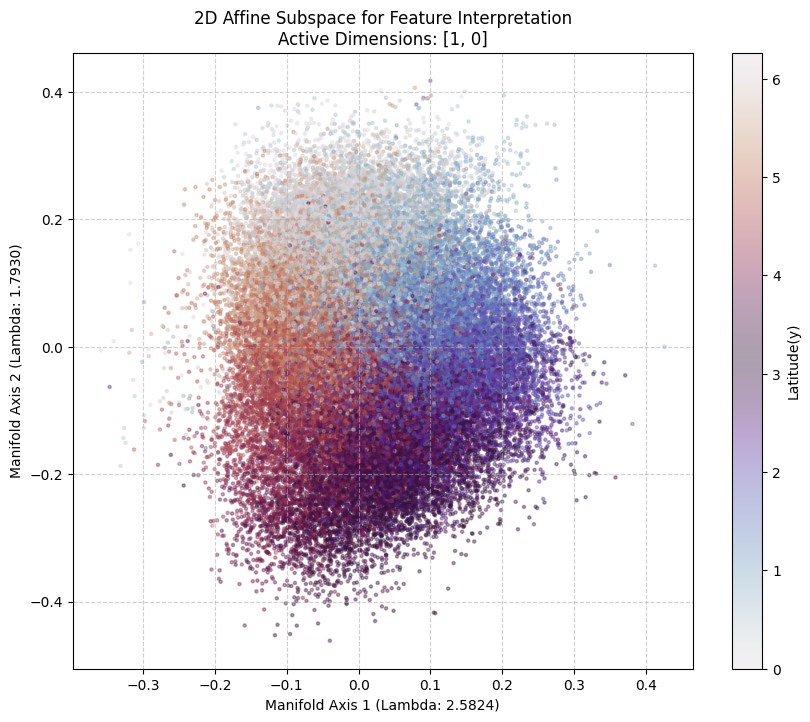

____________________________
Results saved to T_geometry_results.csv
____________________________
[Parameter containing:
tensor([[ 9.5081e-01,  1.2530e-01, -3.2526e-02,  ..., -1.7244e-02,
          4.6760e-03,  1.2365e-02],
        [-3.6338e-02,  5.4370e-01,  2.2830e-02,  ..., -6.1193e-03,
         -7.3719e-02,  2.1193e-02],
        [ 9.1223e-03, -2.3750e-03,  9.8327e-01,  ..., -1.9890e-02,
         -3.4566e-03, -1.2626e-02],
        ...,
        [-1.5984e-02,  2.7202e-02, -1.5829e-04,  ...,  9.6776e-01,
         -2.0240e-02, -2.5212e-02],
        [-3.2407e-02,  4.4843e-02,  2.6076e-04,  ...,  2.4201e-02,
          9.1133e-01,  1.9341e-02],
        [-7.8306e-03, -2.3601e-02,  1.0681e-02,  ...,  1.8309e-02,
         -1.4197e-02,  9.7229e-01]], device='cuda:0', requires_grad=True), Parameter containing:
tensor([[ 9.4437e-01, -1.4678e-02, -2.2027e-02,  ..., -2.5330e-02,
         -2.9075e-02, -3.3297e-02],
        [-3.1609e-02,  9.7571e-01, -5.4759e-03,  ...,  3.5333e-03,
         -8.3449e

In [ ]:
import pandas as pd

idx = [2, 4, 6, 8, 10, 12]
R_mats = []
t_vecs = []
lambda_vecs = []
target_lambda = 2
epsilon = 1e-1

for id in idx:
  path = "/content/drive/MyDrive/terraLatents/latents_" + str(id) + "_92160_for_intervention.pt"
  print(path)
  data = torch.load(path, map_location=device)
  saved_latents = data["latents"]
  saved_meta = data["meta"]
  lats = saved_meta[:, 0]
  alts = saved_meta[:, 3]
  X = saved_latents[(lats > 15) & (lats < 66) & (alts < 4000)]
  times = saved_meta[:, -1][(lats > 15) & (lats < 66) & (alts < 4000)]
  sins = torch.sin(times)
  coss = torch.cos(times)
  y = torch.stack([sins, coss], dim=1)

  # --- Retry Mechanism for Lambda Count & Orthogonality ---
  count = 1
  while True:
      H_model, metrics = Geometry_Extraction(X, y, target_lambda=target_lambda, verbose=2, beta_coeff=1.35, alpha_coeff=1.35, out_dim = 2, n_epochs = 150)

      # 1. Check Lambda count
      nonzero_count = torch.sum(H_model.lambda_vec.abs() > epsilon).item()

      # 2. Check Orthogonality: ||R^T * R - I||
      R = H_model.rotation_matrix
      RT_R = torch.matmul(R.t(), R)
      identity = torch.eye(R.size(1), device=R.device)
      ortho_error = torch.norm(RT_R - identity, p=2).item()

      if nonzero_count <= target_lambda and ortho_error < epsilon:
          break
      elif count > 3:
          print(f'RED FLAG for {path}')
          print(f"Final: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
      print(f"Retrying: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
  # -------------------------------------------------------

  H_model.eval()
  R_mats.append(H_model.rotation_matrix)
  t_vecs.append(H_model.t_vec)
  lambda_vecs.append(H_model.lambda_vec)
  with torch.no_grad():
      X_centered = X.to(device) + H_model.t_vec
      X_rotated = torch.matmul(X_centered, H_model.rotation_matrix)

      top_2_indices = torch.argsort(H_model.lambda_vec.abs(), descending=True)[:2]
      active_dims = X_rotated[:, top_2_indices].cpu().numpy()

      scales = H_model.lambda_vec[top_2_indices].cpu().numpy()
      print(f"Top 2 Lambda scales: {scales}")

  plt.figure(figsize=(10, 8))
  sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
               c=times.cpu().numpy(), cmap='twilight', s=5, alpha=0.4)

  plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
  plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
  plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
  plt.colorbar(sc, label='Latitude(y)')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()
  print("_"*28)

# --- Save to CSV ---
results_df = pd.DataFrame({
    'idx': idx,
    'rotation_matrix': [r.cpu().tolist() for r in R_mats],
    'translation_vec': [t.cpu().tolist() for t in t_vecs],
    'lambda_vec': [l.cpu().tolist() for l in lambda_vecs]
})
results_df.to_csv("T_geometry_results.csv", index=False)
print("Results saved to T_geometry_results.csv")
print("_"*28)
print(R_mats)
print("_"*28)
print(t_vecs)
print("_"*28)
print(lambda_vecs)

In [ ]:
iteration = [2, 4, 6, 8, 10, 12]

T_model_moran = [0.0880, 0.0806, 0.0714, 0.2722, 0.2784, 0.2926]

T_model_circcorr = [0.1320, 0.0521, 0.0668, 0.5393, 0.6191, 0.7005]

T_baseline_moran = [0.0761, 0.0716, 0.0725, 0.0711, 0.0588, 0.0261]

T_baseline_circcorr = [0.1014, 0.0801, 0.0657, 0.0813, 0.1321, 0.0780]

Long_model_moran = [0.0676, 0.1010, 0.1168, 0.1560, 0.3685, 0.4485]

Long_model_circcorr = [0.1134, 0.0535, 0.1409, 0.2497, 0.4417, 0.3460]

Long_baseline_moran = [0.0478, 0.0491, 0.0404, 0.0453, 0.0344, 0.0252]

Long_baseline_circcorr = [0.0621, 0.0768, 0.0581, 0.0724, 0.0388, 0.1083]

L_model_moran = [0.4737, 0.5457, 0.6162, 0.7751, 0.8734, 0.9037]

L_baseline_moran = [0.2382, 0.2083, 0.1838, 0.1533, 0.1599, 0.1651]

H_model_moran = [0.7529, 0.7850, 0.8198, 0.8525, 0.8830, 0.9305]

H_baseline_moran = [0.1243, 0.0710, 0.0929, 0.0937, 0.0795, 0.2017]

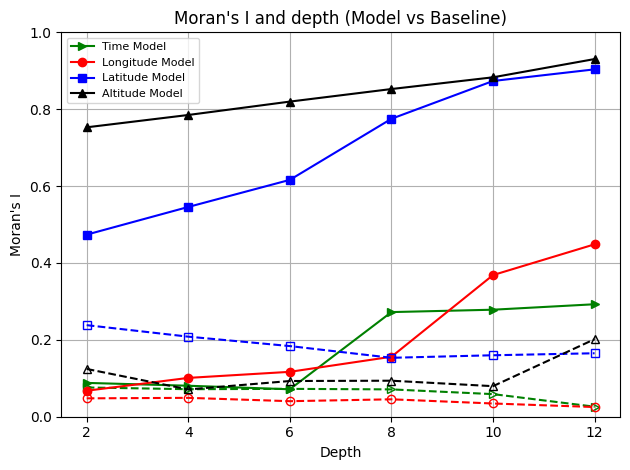

In [ ]:
import matplotlib.pyplot as plt


# Time (green right triangles)
plt.plot(iteration, T_model_moran, marker='>', color='green', label='Time Model')
plt.plot(iteration, T_baseline_moran, marker='>', linestyle='--',
         markerfacecolor='none', markeredgecolor='green', color='green')

# Longitude (red circles)
plt.plot(iteration, Long_model_moran, marker='o', color='red', label='Longitude Model')
plt.plot(iteration, Long_baseline_moran, marker='o', linestyle='--',
         markerfacecolor='none', markeredgecolor='red', color='red')

# Latitude (blue squares)
plt.plot(iteration, L_model_moran, marker='s', color='blue', label='Latitude Model')
plt.plot(iteration, L_baseline_moran, marker='s', linestyle='--',
         markerfacecolor='none', markeredgecolor='blue', color='blue')

# Altitude (black upward triangles)
plt.plot(iteration, H_model_moran, marker='^', color='black', label='Altitude Model')
plt.plot(iteration, H_baseline_moran, marker='^', linestyle='--',
         markerfacecolor='none', markeredgecolor='black', color='black')

plt.ylim(0, 1)
plt.xlabel("Depth")
plt.ylabel("Moran's I")
plt.title("Moran's I and depth (Model vs Baseline)")
plt.legend(loc='upper left', fontsize=8)
plt.grid(True)
plt.tight_layout()

plt.show()

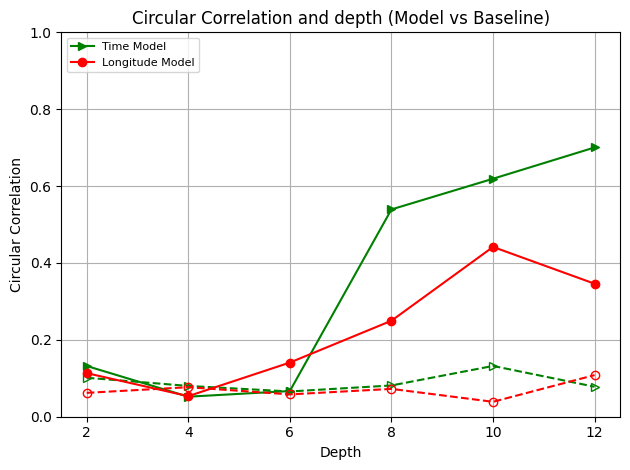

In [ ]:
import matplotlib.pyplot as plt


# Time (green right triangles)
plt.plot(iteration, T_model_circcorr, marker='>', color='green', label='Time Model')
plt.plot(iteration, T_baseline_circcorr, marker='>', linestyle='--',
         markerfacecolor='none', markeredgecolor='green', color='green')

# Longitude (red circles)
plt.plot(iteration, Long_model_circcorr, marker='o', color='red', label='Longitude Model')
plt.plot(iteration, Long_baseline_circcorr, marker='o', linestyle='--',
         markerfacecolor='none', markeredgecolor='red', color='red')

plt.ylim(0, 1)
plt.xlabel("Depth")
plt.ylabel("Circular Correlation")
plt.title("Circular Correlation and depth (Model vs Baseline)")
plt.legend(loc='upper left', fontsize=8)
plt.grid(True)
plt.tight_layout()

plt.show()

/content/drive/MyDrive/terraLatents/latents_10_92160_for_intervention.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.3272    23.0602  | 76.5258  | 0.4140   | 192/192
5      | 0.5028    78.4967  | 20.7571  | 0.7462   | 192/192
10     | 0.5008    74.1485  | 25.0355  | 0.8160   | 192/192
15     | 0.4879    71.4010  | 27.7859  | 0.8131   | 192/192
20     | 0.4600    73.1475  | 26.0517  | 0.8008   | 162/192
25     | 0.4202    78.6242  | 20.7280  | 0.6478   | 102/192
30     | 0.3830    84.7804  | 14.5722  | 0.6474   | 57/192
35     | 0.3678    89.0747  | 10.3114  | 0.6139   | 43/192
40     | 0.3546    91.1031  | 8.3244   | 0.5725   | 30/192
45     | 0.3549    91.5486  | 7.8403   | 0.6111   | 26/192
50     | 0.3461    91.4285  | 7.9400   | 0.6315   | 22/192
55     | 0.3489    91.5403  | 7.8002   | 0.6595   | 21/192
60     | 0.3441    91.4459  | 7.9359   | 0.6182   | 20/192
65     | 0.

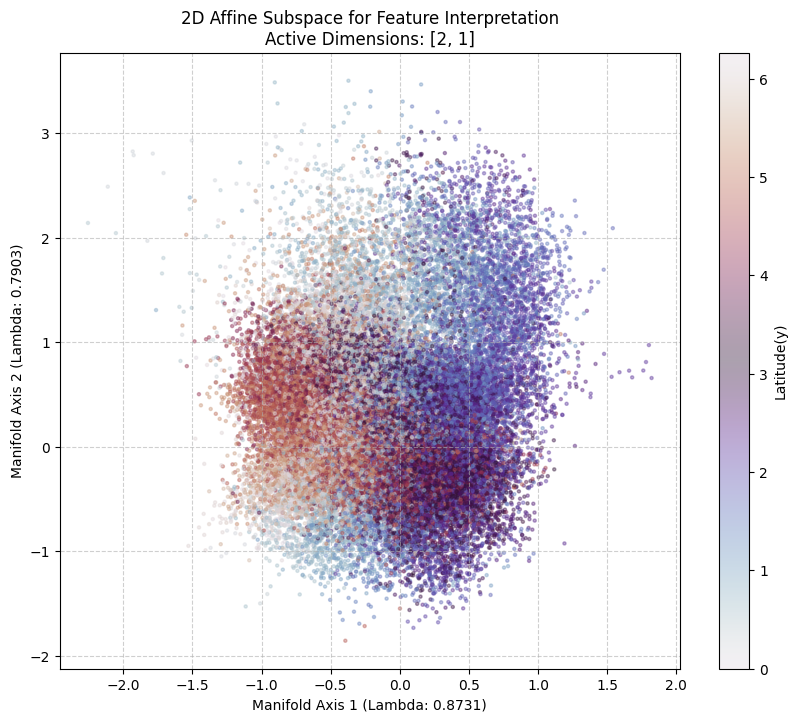

____________________________
Results saved to T_10_geometry_results.csv
____________________________
[Parameter containing:
tensor([[ 0.9670, -0.0376, -0.0451,  ...,  0.0190, -0.0056, -0.0040],
        [ 0.0027,  0.3348, -0.1297,  ..., -0.1382,  0.1014, -0.0137],
        [ 0.0341, -0.0721,  0.5294,  ...,  0.0407,  0.0261,  0.0317],
        ...,
        [ 0.0032,  0.1161, -0.0338,  ...,  0.9575,  0.0037, -0.0142],
        [-0.0021, -0.0765, -0.0448,  ..., -0.0066,  0.9312, -0.0073],
        [ 0.0132,  0.0427, -0.0516,  ..., -0.0071, -0.0061,  0.9818]],
       device='cuda:0', requires_grad=True)]
____________________________
[Parameter containing:
tensor([-0.2115, -0.0342,  0.0047, -0.0878, -0.0969, -0.1126, -0.0839, -0.0145,
        -0.1348, -0.2735, -0.1939, -0.0452, -0.1148, -0.0233, -0.2929, -0.0884,
        -0.0887,  0.0037, -0.0423, -0.0809, -0.1281, -0.2573, -0.1669, -0.0893,
        -0.0530, -0.1620, -0.0289, -0.0887, -0.0559, -0.1439, -0.0718, -0.0767,
        -0.1538, -0.1508,

In [ ]:
import pandas as pd

idx = [10]
R_mats = []
t_vecs = []
lambda_vecs = []
target_lambda = 2
epsilon = 1e-1

for id in idx:
  path = "/content/drive/MyDrive/terraLatents/latents_" + str(id) + "_92160_for_intervention.pt"
  print(path)
  data = torch.load(path, map_location=device)
  saved_latents = data["latents"]
  saved_meta = data["meta"]
  lats = saved_meta[:, 0]
  alts = saved_meta[:, 3]
  X = saved_latents[(lats > 15) & (lats < 66) & (alts < 4000)]
  times = saved_meta[:, -1][(lats > 15) & (lats < 66) & (alts < 4000)]
  sins = torch.sin(times)
  coss = torch.cos(times)
  y = torch.stack([sins, coss], dim=1)
  #y = times

  # --- Retry Mechanism for Lambda Count & Orthogonality ---
  count = 1
  while True:
      H_model, metrics = Geometry_Extraction(X, y, target_lambda=target_lambda, verbose=2, beta_coeff=1.35, alpha_coeff=1.35, out_dim = 2, n_epochs = 150)

      # 1. Check Lambda count
      nonzero_count = torch.sum(H_model.lambda_vec.abs() > epsilon).item()

      # 2. Check Orthogonality: ||R^T * R - I||
      R = H_model.rotation_matrix
      RT_R = torch.matmul(R.t(), R)
      identity = torch.eye(R.size(1), device=R.device)
      ortho_error = torch.norm(RT_R - identity, p=2).item()

      if nonzero_count <= target_lambda and ortho_error < epsilon:
          break
      elif count > 3:
          print(f'RED FLAG for {path}')
          print(f"Final: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
      print(f"Retrying: Nonzero Lambdas={nonzero_count} (target <= {target_lambda}), Ortho Error={ortho_error:.6f}")
  # -------------------------------------------------------

  H_model.eval()
  R_mats.append(H_model.rotation_matrix)
  t_vecs.append(H_model.t_vec)
  lambda_vecs.append(H_model.lambda_vec)
  with torch.no_grad():
      X_centered = X.to(device) + H_model.t_vec
      X_rotated = torch.matmul(X_centered, H_model.rotation_matrix)

      top_2_indices = torch.argsort(H_model.lambda_vec.abs(), descending=True)[:2]
      active_dims = X_rotated[:, top_2_indices].cpu().numpy()

      scales = H_model.lambda_vec[top_2_indices].cpu().numpy()
      print(f"Top 2 Lambda scales: {scales}")

  plt.figure(figsize=(10, 8))
  sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
               c=times.cpu().numpy(), cmap='twilight', s=5, alpha=0.4)

  plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
  plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
  plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
  plt.colorbar(sc, label='Latitude(y)')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()
  print("_"*28)

# --- Save to CSV ---
results_df = pd.DataFrame({
    'idx': idx,
    'rotation_matrix': [r.cpu().tolist() for r in R_mats],
    'translation_vec': [t.cpu().tolist() for t in t_vecs],
    'lambda_vec': [l.cpu().tolist() for l in lambda_vecs]
})
results_df.to_csv("T_10_geometry_results.csv", index=False)
print("Results saved to T_10_geometry_results.csv")
print("_"*28)
print(R_mats)
print("_"*28)
print(t_vecs)
print("_"*28)
print(lambda_vecs)